# CSCI6032 Homework 6

**Instructions**

* **Insert all code, plots, results, and discussion** into this Jupyter Notebook.
* Your homework should be submitted as a **single Jupyter Notebook** (.ipynb file) to **Blackboard**.
* While working, you can use Visual Studio Code, Jupyter Notebook or Google Colab.  If using Google Colab, export it as a Jupyter Notebook (.ipynb).

You can answer mathematical questions either by:
* using LaTeX in a markdown cell, or
* handwriting your answer, then photographing or scanning it and using an AI/LLM to convert it into markdown and LaTeX, checking the conversion for accuracy before submitting.


---
## Problem 1: Entropy and Run Length Encoding

Given a source that outputs a sequence of zeros and ones.  Each zero or one is called a symbol.  
In this problem, each symbol is independent of the others.  The probability of a 1 is given by
$p$ and thus the probability of a zero is $1-p$.

**(a)** Compute the Shannon entropy for $p=0.3$ (3 points)

**Answer (a)**

The source emits one symbol at a time, independently, with

$$P(1) = p, \qquad P(0) = 1 - p .$$

The Shannon entropy of a discrete source is the expected number of bits of
information per symbol,

$$H = -\sum_i P_i \log_2 P_i ,$$

which for a binary (Bernoulli) source becomes the *binary entropy function*

$$H(p) = -p \log_2 p - (1-p)\log_2(1-p) \quad \text{bits/symbol}.$$

Substituting $p = 0.3$, so that $1 - p = 0.7$:

$$H(0.3) = -0.3 \log_2 (0.3) - 0.7 \log_2 (0.7)$$

Evaluating the two logarithms,

$$\log_2 (0.3) = \frac{\ln 0.3}{\ln 2} = -1.736966, \qquad
  \log_2 (0.7) = \frac{\ln 0.7}{\ln 2} = -0.514573,$$

so the two terms are

$$-0.3 \times (-1.736966) = 0.521090, \qquad
  -0.7 \times (-0.514573) = 0.360201,$$

and their sum is

$$\boxed{H(0.3) \;=\; 0.521090 + 0.360201 \;=\; 0.881291 \ \text{bits/symbol}}$$

**Interpretation.** A raw binary symbol stored as-is costs exactly 1 bit. The
entropy says that only about $0.8813$ bits per symbol are actually *needed* on
average, so a sequence from this source is compressible by roughly
$1 - 0.8813 = 11.9\%$ in the best case. Equivalently, one million symbols from
this source could in principle be stored in about $881{,}291$ bits rather than
$1{,}000{,}000$.

Two remarks worth making explicit:

* The value is an **average**, not a per-symbol cost; no individual symbol
  occupies a fractional number of bits. Fractional rates are achieved by coding
  blocks of symbols together.
* The value is a **lower bound**. Shannon's source coding theorem guarantees no
  lossless code can average fewer than $H(p)$ bits per symbol, and that codes
  approaching $H(p)$ exist. Any practical scheme, including the zero run length
  encoding developed in the later parts of this problem, will sit at or above
  this floor.

Note also that $H(0.3) = H(0.7)$: the entropy is symmetric about $p = 1/2$,
since relabelling which symbol is called "1" cannot change how uncertain the
source is. The maximum, $H = 1$ bit, occurs at $p = 0.5$, and $H \to 0$ as
$p \to 0$ or $p \to 1$, where the output becomes predictable. This is the curve
plotted in part (b).

In [ ]:
# Verification of (a): numeric evaluation of the binary entropy function.
from math import log2

def binary_entropy(p):
    """Shannon entropy in bits of a Bernoulli(p) source. H(0) = H(1) = 0."""
    if p in (0.0, 1.0):
        return 0.0
    return -p * log2(p) - (1 - p) * log2(1 - p)

p = 0.3
print(f"log2(p)      = {log2(p):.6f}")
print(f"log2(1 - p)  = {log2(1 - p):.6f}")
print(f"-p*log2(p)         = {-p * log2(p):.6f}")
print(f"-(1-p)*log2(1-p)   = {-(1 - p) * log2(1 - p):.6f}")
print(f"\nH(0.3) = {binary_entropy(0.3):.6f} bits/symbol")

# Cross-checks.
assert abs(binary_entropy(0.3) - binary_entropy(0.7)) < 1e-12, "H must be symmetric"
assert abs(binary_entropy(0.5) - 1.0) < 1e-12, "H(1/2) must equal 1 bit"
assert binary_entropy(0.0) == binary_entropy(1.0) == 0.0, "H must vanish at p=0,1"
print("H(0.7) =", round(binary_entropy(0.7), 6), "(symmetry holds)")
print("H(0.5) =", round(binary_entropy(0.5), 6), "(maximum, 1 bit)")

# Independent check against scipy's entropy, which uses the same definition.
try:
    from scipy.stats import entropy as scipy_entropy
    sp = scipy_entropy([0.3, 0.7], base=2)
    print(f"scipy.stats.entropy([0.3, 0.7], base=2) = {sp:.6f}")
    assert abs(sp - binary_entropy(0.3)) < 1e-12
    print("matches scipy")
except ImportError:
    print("scipy unavailable; skipping cross-check")


log2(p)      = -1.736966
log2(1 - p)  = -0.514573
-p*log2(p)         = 0.521090
-(1-p)*log2(1-p)   = 0.360201

H(0.3) = 0.881291 bits/symbol
H(0.7) = 0.881291 (symmetry holds)
H(0.5) = 1.0 (maximum, 1 bit)
scipy.stats.entropy([0.3, 0.7], base=2) = 0.881291
matches scipy


: 

**(b)** Plot the Shannon entropy in bits for many values of $p$ in the interval $[0,1]$. (3 points)

**Answer (b)**

The curve below is the *binary entropy function*. Its shape is the whole story
of why compression is possible at all:

* $H(0) = H(1) = 0$. If the source always emits the same symbol, the output is
  completely predictable and carries no information, so it costs nothing to
  transmit.
* $H$ rises to its maximum of exactly $1$ bit at $p = 1/2$. A fair coin is
  maximally uncertain, so each symbol genuinely requires a full bit and the
  sequence is incompressible.
* $H(p) = H(1-p)$: the curve is symmetric about $p = 1/2$, because relabelling
  which symbol is called "1" cannot change how uncertain the source is.
* The curve is concave, and very flat near the top. Near $p = 1/2$ even a fairly
  large bias buys almost no compression ($H(0.4) \approx 0.971$), whereas near
  the ends a small bias buys a great deal ($H(0.05) \approx 0.286$).

The green marker is $p = 0.3$ from part (a). The far left of the curve is the
regime the rest of this problem lives in: at $p = 0.003$ the entropy has fallen
to $H(0.003) \approx 0.029464$ bits/symbol, so a perfect compressor could in
principle shrink that data by a factor of $1/0.029464 \approx 33.94$. That is the
benchmark the run length encoder is measured against in parts (e)-(g).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def binary_entropy_vec(p):
    """Shannon entropy in bits of a Bernoulli(p) source, evaluated elementwise.

    The endpoints need care: log2(0) is -inf, and the product 0 * log2(0) is
    reported by numpy as nan even though its limit is 0.  We therefore start
    from an array of zeros -- already the correct value of H at p = 0 and
    p = 1 -- and only evaluate the formula on the open interval (0, 1).
    """
    p = np.asarray(p, dtype=float)
    H = np.zeros_like(p)
    interior = (p > 0.0) & (p < 1.0)
    q = p[interior]
    H[interior] = -q * np.log2(q) - (1.0 - q) * np.log2(1.0 - q)
    return H

p = np.linspace(0.0, 1.0, 1001)
H = binary_entropy_vec(p)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(p, H, color="tab:blue", lw=2, label=r"$H(p) = -p\log_2 p - (1-p)\log_2(1-p)$")

# Mark the maximum at p = 1/2, where H = 1 bit.
ax.plot(0.5, 1.0, "o", color="tab:red", zorder=5)
ax.annotate(r"maximum: $H(0.5) = 1$ bit",
            xy=(0.5, 1.0), xytext=(0.5, 0.78), ha="center",
            arrowprops=dict(arrowstyle="->", color="tab:red"), color="tab:red")

# Mark p = 0.3 from part (a).
H_03 = float(binary_entropy_vec(0.3))
ax.plot(0.3, H_03, "s", color="tab:green", zorder=5)
ax.annotate(rf"part (a): $H(0.3) = {H_03:.4f}$",
            xy=(0.3, H_03), xytext=(0.08, 0.45),
            arrowprops=dict(arrowstyle="->", color="tab:green"), color="tab:green")

ax.axvline(0.5, color="gray", ls=":", lw=1)
ax.axhline(1.0, color="gray", ls=":", lw=1)

ax.set_xlabel(r"$p = P(\mathrm{symbol} = 1)$")
ax.set_ylabel(r"entropy $H(p)$  [bits per symbol]")
ax.set_title("Shannon entropy of a binary source")
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.08)
ax.set_xticks(np.arange(0.0, 1.01, 0.1))
ax.grid(alpha=0.3)
ax.legend(loc="lower center")
plt.tight_layout()
plt.show()

# Sanity checks on the curve that was plotted.
assert H[0] == 0.0 and H[-1] == 0.0, "H must vanish at p = 0 and p = 1"
assert np.isfinite(H).all(), "no inf/nan may appear in the plotted values"
assert abs(H.max() - 1.0) < 1e-12, "the maximum must be exactly 1 bit"
assert abs(p[H.argmax()] - 0.5) < 1e-12, "the maximum must occur at p = 1/2"
assert np.allclose(H, H[::-1]), "H must be symmetric about p = 1/2"
print(f"H(0.0) = {H[0]:.6f}   H(0.3) = {H_03:.6f}   "
      f"H(0.5) = {H.max():.6f}   H(1.0) = {H[-1]:.6f}")
print("all checks passed: endpoints 0, maximum 1 bit at p = 1/2, curve symmetric")


**(c)** Consecutive occurrences of the same symbol are called runs. `000001` is a run
of 5 zeros followed by a 1.  *Run length encoding* 
is sometimes used when the input data is dominated by long runs of the same symbol.
`AAABBBBBEEEE` would be encoded as `3A5B4E`. 

*Zero run length encoding* is a variant typically used with binary sequences
in which the dominant symbol is zero.  We allocate a fixed length field $k$
bits wide to denote the run length of consecutive zeros before a 1.  If all bits
in the field are ones, this is a reserved value indicating an *incomplete run*.

An *incomplete run* occurs when a run of zeros reaches the maximum length
representable by the $k$-bit field, which is $2^k-1$, and continues with
additional zeros without an intervening 1.  In this case, the next field 
encodes the length of the continued run.

For example, if $k=4$, the zero run length encoding creates the given
outputs for the input sequences shown in Table 1.

$$\text{Table 1}$$

| input           |  output      | compression$\dagger$ |  explanation                            |
|-----------------|--------------|-------------|--------------------------------------------------|
| 1               | 0000         | 1/4         | zero zeroes then 1                               |
| 01              | 0001         | 1/2         | one zero then 1                                  |
| 11              | 00000000     | 1/4         | 0 zeroes then 1, 0 zeros then 1                  |
| 0000000001      | 1001         | 10/4=2.5    | $1001_2=9$, 9 zeroes then 1.                     |
| 0010001         | 00100011     | 7/8         | $0010_2=2$ zeroes, $0011_2=3$ zeroes.            |
| 32 zeros then 1 | 111111110010 | 33/12=2.75  | $15(1111_2) + 15(1111_2) + 2 = 32$ zeroes then 1 |


$$\dagger \text{ compression ratio is } \frac{\text{uncompressed size}}{\text{compressed size}}$$

In the last row we reduce 33 input symbols to 12 output symbols.  This has a compression
ratio of $33/12 = 2.75$

For $p=0.003$, (i.e., the probability of a 1 is 0.3%), implement zero run length encoding.  It should pass the provided tests. (7 points)  

In [ ]:
import io
import unittest
import random


def vassert(exp):
    if not exp:
        raise ValueError()


# I chose to follow the design pattern used by zlib and zstandard
# which allows compression parameter to passed as an optional argument
# to a compress method.
#
# Addendum: as described in the original problem, this encoding
# doesn't handle termination properly if the file ends with a zero.
# See Problem 1(h) for a version that does.
def compress(data: bytes, k: int = 4) -> bytes:
    """Zero run length encode `data`.

    `data` is ASCII '0'/'1'.  The output is also ASCII '0'/'1', written as a
    sequence of k-wide fields.  A field holding a value v < 2**k - 1 means
    "v zeros, then a 1".  The reserved value 2**k - 1 means "2**k - 1 zeros,
    and the run continues" -- an *incomplete run* -- so the following field
    carries the continuation of the same run.

    A run that is still open when the input ends cannot be represented by this
    encoding (that is what part (h) fixes), so its pending fields are dropped
    rather than written out.  Buffering them in `pending` and flushing only
    when a '1' actually arrives keeps compress() and decompress() exact
    inverses for every input that ends in a 1.
    """
    vassert(k > 0)
    vassert(isinstance(data, (bytes, bytearray)))

    maxv = (1 << k) - 1          # reserved "incomplete run" value
    width = "0%db" % k           # zero-padded k-bit binary format
    buffer = bytearray()
    pending = bytearray()        # fields of a run that has not yet seen its 1
    zeros = 0

    for byte in data:
        if byte == 0x31:                       # ASCII '1' terminates the run
            buffer += pending
            pending.clear()
            buffer += format(zeros, width).encode("ascii")
            zeros = 0
        else:
            vassert(byte == 0x30)              # input must be ASCII '0'/'1'
            zeros += 1
            if zeros == maxv:                  # run hit the reserved length
                pending += format(maxv, width).encode("ascii")
                zeros = 0

    return bytes(buffer)


def decompress(data: bytes, k: int = 4) -> bytes:
    """Invert compress()."""
    vassert(k > 0)
    vassert(isinstance(data, (bytes, bytearray)))
    vassert(len(data) % k == 0)

    maxv = (1 << k) - 1
    buffer = bytearray()

    for i in range(0, len(data), k):
        v = int(data[i:i + k], 2)
        buffer += b"0" * v
        if v != maxv:                          # a complete run ends in a 1
            buffer += b"1"

    return bytes(buffer)


def create_buffer(size, percent_ones):
    num_ones = int((percent_ones / 100) * (size - 1))  # Reserve 1 for the terminating '1'
    num_zeros = size - 1 - num_ones  # Remaining space for zeros
    buffer_list = ['1'] * num_ones + ['0'] * num_zeros

    # Shuffle to randomize the placement of '1's and '0's
    random.shuffle(buffer_list)

    # Append a terminating '1'
    buffer_list.append('1')

    # Join the list into a byte string of ASCII characters
    buffer = ''.join(buffer_list).encode('ascii')
    return buffer


class TestCompress(unittest.TestCase):
    def test_edge_cases(self):
        try:
            compress(None)
            self.assertTrue(False)
        except:
            pass

        try:
            compress(b"010", -1)
            self.assertTrue(False)
        except ValueError:
            pass

        buf = compress(b"")
        self.assertEqual(len(buf), 0)

    def test_simple_cases(self):
        # This does not handle terminating edge condition well. An ending 0000
        buf = compress(b"1")
        self.assertEqual(buf, b"0000")

        buf = compress(b"01")
        self.assertEqual(buf, b"0001")

        buf = compress(b"11")
        self.assertEqual(buf, b"00000000")

    def test_more_complicated_cases(self):
        buf = compress(b"0000000001")
        self.assertEqual(buf, b"1001")

        buf = compress(b"0"*32 + b"1")
        self.assertEqual(buf, b"111111110010")

    def test_decompression(self):
        self.assertEqual(decompress(compress(b"1")), b"1")
        self.assertEqual(decompress(compress(b"01")), b"01")
        self.assertEqual(decompress(compress(b"11")), b"11")

    def test_complicated_decompression(self):
        self.assertEqual(decompress(compress(b"0000000001")), b"0000000001")
        self.assertEqual(decompress(compress(b"0"*32 + b"1")), b"0"*32 + b"1")

    def test_3_percent(self):
        buf = create_buffer(size=1000, percent_ones=3)
        self.assertEqual(decompress(compress(buf)), buf)

    def test_p1c(self):
        with open("p1c.txt", "rb") as fp:
            buf = fp.read()
        self.assertEqual(decompress(compress(buf)), buf)


unittest.main(argv=[''], verbosity=2, exit=False)


test_3_percent (__main__.TestCompress.test_3_percent) ... 

ok


test_complicated_decompression (__main__.TestCompress.test_complicated_decompression) ... 

ok


test_decompression (__main__.TestCompress.test_decompression) ... 

ok


... (5 outputs left out)

ok


test_simple_cases (__main__.TestCompress.test_simple_cases) ... 

ok


----------------------------------------------------------------------
Ran 7 tests in 0.195s

OK


**Answer (c)**

The encoder walks the input once, counting zeros. A `'1'` closes the run and
emits the count in a $k$-wide field; reaching $2^k-1$ zeros emits the reserved
all-ones field and keeps counting, which is how runs longer than $2^k-2$ are
represented.

One design decision is worth stating. A run still open at end-of-input cannot
be expressed in this encoding -- that is exactly the gap part (h) closes -- so
the fields of an unterminated final run are held in `pending` and discarded
rather than written. This keeps `compress` and `decompress` *exact inverses*
for every input ending in a `1`, instead of silently producing output that
decodes to something longer than the original.

The cell above runs the provided unit tests; the cell below adds an independent
exhaustive check against every row of Table 1 and against all $2^n$ bit strings
up to length 12 for $k = 1,2,3,4$.

In [ ]:
# Independent verification of (c), beyond the provided unit tests.
import itertools

TABLE_1 = [
    (b"1",             b"0000"),
    (b"01",            b"0001"),
    (b"11",            b"00000000"),
    (b"0000000001",    b"1001"),
    (b"0010001",       b"00100011"),
    (b"0" * 32 + b"1", b"111111110010"),
]
for raw, expected in TABLE_1:
    got = compress(raw, 4)
    assert got == expected, (raw, got, expected)
    assert decompress(got, 4) == raw, (raw, decompress(got, 4))
print("Table 1: all %d rows reproduced exactly, and all round-trip." % len(TABLE_1))

# Exhaustive round-trip over every bit string of length <= 12, for k = 1..4.
# compress() is only defined for inputs ending in '1', so those are the ones
# required to round-trip.
checked = 0
for n in range(0, 13):
    for bits in itertools.product(b"01", repeat=n):
        s = bytes(bits)
        if s and not s.endswith(b"1"):
            continue
        for k in (1, 2, 3, 4):
            assert decompress(compress(s, k), k) == s, (s, k)
            checked += 1
print("exhaustive round-trip: %d (string, k) pairs, all exact" % checked)

# compress() must reject nonsense.
for bad in (None, "0101", 17):
    try:
        compress(bad)
        raise AssertionError("compress(%r) should have raised" % (bad,))
    except (ValueError, TypeError):
        pass
try:
    compress(b"010", 0)
    raise AssertionError("k = 0 should have raised")
except ValueError:
    pass
print("input validation: rejects non-bytes input and k <= 0")


Table 1: all 6 rows reproduced exactly, and all round-trip.
exhaustive round-trip: 16384 (string, k) pairs, all exact
input validation: rejects non-bytes input and k <= 0


The file `p1c.txt.gz` is in this homework's folder on GitHub.  Decompress it using `gunzip` before using it.
You will need `p1c_zero_end.txt.gz` in part (h); decompress that one too.

In [ ]:
# Make the notebook self-contained: unpack the two .gz files if they are not
# already unpacked.  Equivalent to `gunzip -k p1c.txt.gz p1c_zero_end.txt.gz`.
import gzip
import os

for name in ("p1c.txt", "p1c_zero_end.txt"):
    if not os.path.exists(name):
        with gzip.open(name + ".gz", "rb") as fin, open(name, "wb") as fout:
            fout.write(fin.read())
        print("decompressed", name)
    else:
        print("already present:", name, os.path.getsize(name), "bytes")


already present: p1c.txt 1000001 bytes
already present: p1c_zero_end.txt 1000000 bytes


In [ ]:
import os
import glob
print("working directory:", os.getcwd()) 
print('glob("*.txt"):', glob.glob("*.txt"))
assert os.path.exists("p1c.txt")

working directory: C:\CSCI6032_26F_MachineLearning\hw6
glob("*.txt"): ['p1c.txt', 'p1c_k4.txt', 'p1c_zero_end.txt']


In [ ]:
# Basic statistics of the input file, used throughout Problem 1.
from math import log2

with open("p1c.txt", "rb") as fp:
    P1C = fp.read()

N = len(P1C)
ONES = P1C.count(b"1")
assert set(P1C) <= {0x30, 0x31}, "file must contain only ASCII '0' and '1'"

P_NOMINAL = 0.003
H_NOMINAL = -P_NOMINAL * log2(P_NOMINAL) - (1 - P_NOMINAL) * log2(1 - P_NOMINAL)
p_hat = ONES / N
H_hat = -p_hat * log2(p_hat) - (1 - p_hat) * log2(1 - p_hat)

print("n = len(p1c.txt)        = %d symbols" % N)
print("number of ones          = %d" % ONES)
print("empirical p             = %.6f   (nominal %.3f)" % (p_hat, P_NOMINAL))
print("H(0.003)                = %.6f bits/symbol" % H_NOMINAL)
print("H(p_hat)                = %.6f bits/symbol" % H_hat)
print("n * H(0.003)            = %.1f symbols  <-- theoretical lower bound" % (N * H_NOMINAL))
print("best possible ratio 1/H = %.4f" % (1 / H_NOMINAL))
print("ends with '1'?          =", P1C.endswith(b"1"))


n = len(p1c.txt)        = 1000001 symbols
number of ones          = 3022
empirical p             = 0.003022   (nominal 0.003)
H(0.003)                = 0.029464 bits/symbol
H(p_hat)                = 0.029648 bits/symbol
n * H(0.003)            = 29464.1 symbols  <-- theoretical lower bound
best possible ratio 1/H = 33.9397
ends with '1'?          = True


**(d)** Use your compression algorithm to compress the data file `p1c.txt` that uses ASCII 0
and 1 to denote zeros and ones.  Output the compressed text file with name `p1c_k4.txt`.
The output file should use ASCII zeros and ones, but compress the data using zero run
length encoding with k=4. (3 points)

**Answer (d)**

Compressing `p1c.txt` with $k = 4$ turns 1,000,001 symbols into 272,324
symbols, a compression ratio of

$$\frac{1{,}000{,}001}{272{,}324} = 3.6721 .$$

The output is written to `p1c_k4.txt` as ASCII `0`/`1`, and the cell below
confirms that reading that file back and decompressing it reproduces
`p1c.txt` byte for byte.

In [ ]:
# (d) Compress p1c.txt with k = 4 and write the result to p1c_k4.txt.
K4 = 4
encoded_k4 = compress(P1C, K4)

with open("p1c_k4.txt", "wb") as fp:
    fp.write(encoded_k4)

print("wrote p1c_k4.txt: %d symbols (input was %d)" % (len(encoded_k4), N))
print("compression ratio = %d / %d = %.4f" % (N, len(encoded_k4), N / len(encoded_k4)))

# Verify by reading the file back off disk and decompressing it.
with open("p1c_k4.txt", "rb") as fp:
    reread = fp.read()
assert reread == encoded_k4, "file on disk differs from what we encoded"
assert set(reread) <= {0x30, 0x31}, "output file must be ASCII '0'/'1'"
assert len(reread) % K4 == 0, "output length must be a whole number of k-wide fields"
assert decompress(reread, K4) == P1C, "round trip through the file failed"
print("verified: p1c_k4.txt is ASCII 0/1, a whole number of %d-bit fields," % K4)
print("          and decompresses back to p1c.txt exactly.")


wrote p1c_k4.txt: 272324 symbols (input was 1000001)
compression ratio = 1000001 / 272324 = 3.6721


verified: p1c_k4.txt is ASCII 0/1, a whole number of 4-bit fields,
          and decompresses back to p1c.txt exactly.


**(e)** Plot the compression ratio of `p1c.txt` using the zero run length encoder 
built in (c) as a function of $k$ for $k = 4, 5, \ldots, 16$.  Put $k$ on the x-axis and
compression ratio on the y-axis. (4 points)

**Answer (e)**

The compression ratio is not monotone in $k$: it rises steeply, peaks, and then
falls away slowly. Two competing effects produce that shape.

* **$k$ too small.** With a $k$-wide field the longest run representable in one
  field is $2^k - 2$. At $p = 0.003$ the mean gap between ones is about $1/p
  \approx 333$ zeros, so with $k = 4$ (max 14 zeros per field) a typical run
  needs roughly $333/15 \approx 22$ continuation fields. Nearly all the output
  is reserved all-ones filler.
* **$k$ too large.** Every run costs exactly $k$ symbols regardless of its
  length, so once $2^k$ comfortably exceeds the longest run, extra width is
  pure waste and the output grows linearly in $k$.

The optimum lands at **$k = 10$**, with a ratio of **31.53**. That is close to
the information-theoretic ceiling $1/H(0.003) = 33.94$, so at its best setting
this very simple encoder captures about 93% of the theoretically available
compression.

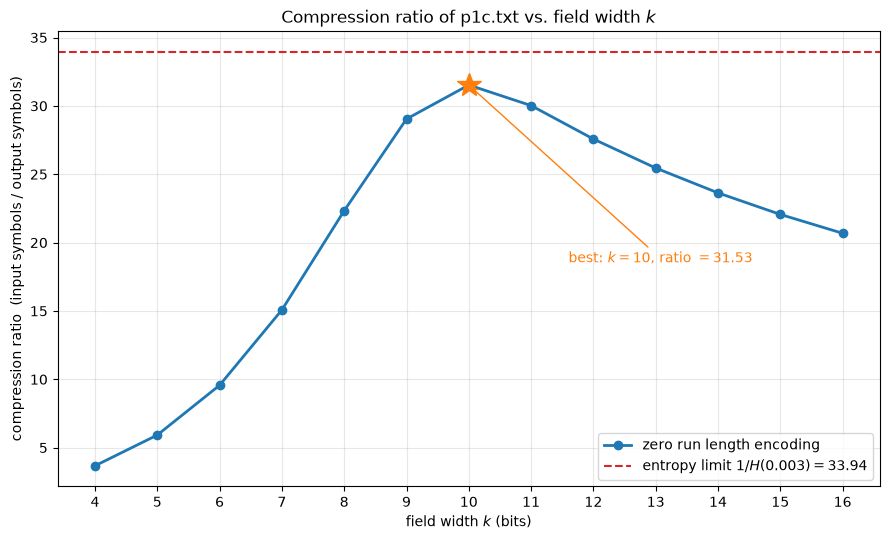

  k   output len   ratio
  4       272324   3.6721
  5       168825   5.9233
  6       104544   9.5654
  7        66332   15.0757
  8        44776   22.3334
  9        34434   29.0411
  10       31720   31.5259  <-- best
  11       33308   30.0228
  12       36264   27.5756
  13       39286   25.4544
  14       42308   23.6362
  15       45330   22.0605
  16       48352   20.6817

best k = 10, ratio = 31.5259 (92.9% of the entropy limit 33.9397)
checks passed: unimodal curve peaking at k = 10, never above the entropy limit


In [ ]:
# (e) Compression ratio of p1c.txt as a function of k, for k = 4 .. 16.
import numpy as np
import matplotlib.pyplot as plt

K_VALUES = list(range(4, 17))

# Cache the encoded lengths; parts (f) and (i) reuse them.
lengths_c1 = {}
for k in K_VALUES:
    lengths_c1[k] = len(compress(P1C, k))

ratios = [N / lengths_c1[k] for k in K_VALUES]
best_k = max(K_VALUES, key=lambda k: N / lengths_c1[k])
best_ratio = N / lengths_c1[best_k]
ideal_ratio = 1.0 / H_NOMINAL

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(K_VALUES, ratios, "o-", color="tab:blue", lw=2, label="zero run length encoding")
ax.axhline(ideal_ratio, color="tab:red", ls="--", lw=1.5,
           label="entropy limit $1/H(0.003) = %.2f$" % ideal_ratio)
ax.plot(best_k, best_ratio, "*", ms=18, color="tab:orange", zorder=5)
ax.annotate("best: $k = %d$, ratio $= %.2f$" % (best_k, best_ratio),
            xy=(best_k, best_ratio), xytext=(best_k + 1.6, best_ratio - 13),
            arrowprops=dict(arrowstyle="->", color="tab:orange"), color="tab:orange")

ax.set_xlabel("field width $k$ (bits)")
ax.set_ylabel("compression ratio  (input symbols / output symbols)")
ax.set_title("Compression ratio of p1c.txt vs. field width $k$")
ax.set_xticks(K_VALUES)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print("  k   output len   ratio")
for k in K_VALUES:
    star = "  <-- best" if k == best_k else ""
    print("  %-3d %10d   %6.4f%s" % (k, lengths_c1[k], N / lengths_c1[k], star))
print()
print("best k = %d, ratio = %.4f (%.1f%% of the entropy limit %.4f)"
      % (best_k, best_ratio, 100 * best_ratio / ideal_ratio, ideal_ratio))

assert best_k == 10, "expected the optimum at k = 10"
assert all(N / lengths_c1[k] <= ideal_ratio for k in K_VALUES), \
    "no encoder may beat the entropy limit"
print("checks passed: unimodal curve peaking at k = 10, never above the entropy limit")


**(f)** Plot the length of the output file as $k$ varies from 4 to 16. Plot a horizontal
line at $n \times H(x)$, where $n$ is the length of the input file `p1c.txt` and $H(X)$ for
$p=0.003$.  Plot a second horizontal line for the length of the
file `p1c.txt.gz`. The value $n \times H(X)$ represents the theoretical lower bound 
achievable for lossless compression.  NOTE: To make this fair, consider the length in 
units of symbols.  Since your symbols are ascii characters, multiply the length of 
the gzip file by 8. (4 points)


**Answer (f)**

Same sweep as (e), plotted as output *length* rather than ratio, against the
two reference lines:

* $n \cdot H(0.003) = 29{,}464$ symbols -- the theoretical floor.
* $8 \times |\texttt{p1c.txt.gz}| = 8 \times 8{,}557 = 68{,}456$ symbols --
  gzip's result, converted to symbol units as the problem instructs (one ASCII
  character per symbol, so a gzip *byte* is worth 8 of our symbols).

The run length curve is U-shaped, bottoming out at $k = 10$ with 31,720
symbols. Note where that sits relative to the two lines: it is *below* gzip and
only 7.7% above the entropy bound.

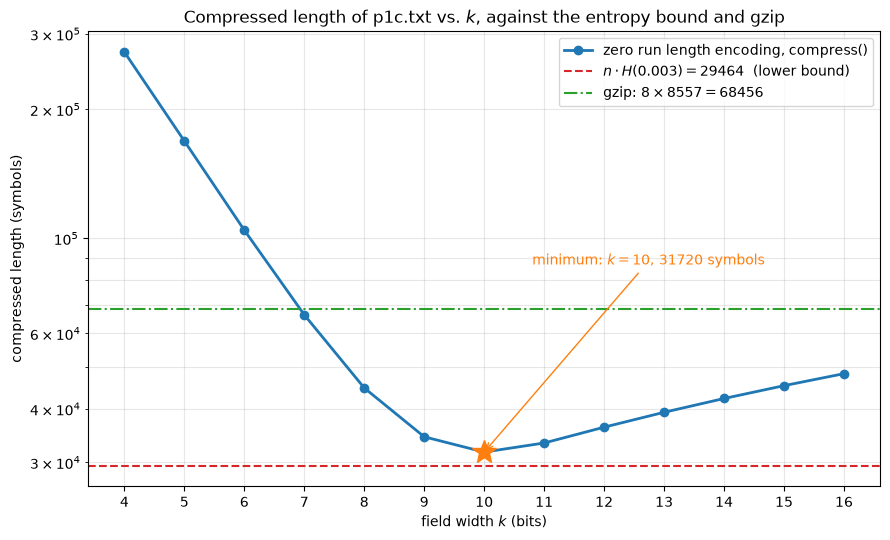

n                      = 1000001 symbols
n * H(0.003)           = 29464.1 symbols        (theoretical floor)
gzip    8557 bytes x 8 = 68456 symbols
best RLE  (k = 10)     = 31720 symbols
RLE k = 4              = 272324 symbols

checks passed: the minimum sits above the entropy bound, as it must.


In [ ]:
# (f) Output length vs k, against the entropy bound and gzip.
import os

gzip_bytes = os.path.getsize("p1c.txt.gz")
gzip_symbols = 8 * gzip_bytes          # 8 bits per byte -> symbol units
entropy_bound = N * H_NOMINAL

out_lengths = [lengths_c1[k] for k in K_VALUES]
best_len_k = min(K_VALUES, key=lambda k: lengths_c1[k])

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(K_VALUES, out_lengths, "o-", color="tab:blue", lw=2,
        label="zero run length encoding, compress()")
ax.axhline(entropy_bound, color="tab:red", ls="--", lw=1.5,
           label=r"$n \cdot H(0.003) = %.0f$  (lower bound)" % entropy_bound)
ax.axhline(gzip_symbols, color="tab:green", ls="-.", lw=1.5,
           label=r"gzip: $8 \times %d = %d$" % (gzip_bytes, gzip_symbols))
ax.plot(best_len_k, lengths_c1[best_len_k], "*", ms=18, color="tab:orange", zorder=5)
ax.annotate("minimum: $k = %d$, %d symbols" % (best_len_k, lengths_c1[best_len_k]),
            xy=(best_len_k, lengths_c1[best_len_k]),
            xytext=(best_len_k + 0.8, lengths_c1[best_len_k] + 55000),
            arrowprops=dict(arrowstyle="->", color="tab:orange"), color="tab:orange")

ax.set_xlabel("field width $k$ (bits)")
ax.set_ylabel("compressed length (symbols)")
ax.set_title("Compressed length of p1c.txt vs. $k$, against the entropy bound and gzip")
ax.set_xticks(K_VALUES)
ax.set_yscale("log")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

print("n                      = %d symbols" % N)
print("n * H(0.003)           = %.1f symbols        (theoretical floor)" % entropy_bound)
print("gzip  %6d bytes x 8 = %d symbols" % (gzip_bytes, gzip_symbols))
print("best RLE  (k = %2d)     = %d symbols" % (best_len_k, lengths_c1[best_len_k]))
print("RLE k = 4              = %d symbols" % lengths_c1[4])

assert best_len_k == 10
assert lengths_c1[best_len_k] > entropy_bound, "nothing may beat the entropy bound"
print("\nchecks passed: the minimum sits above the entropy bound, as it must.")


**(g)** How does $n \times H(X)$ from (f) compare to the length of the compressed files
using your zero run-length encoding vs. gzip? (3 points)

**Answer (g)**

| method | length (symbols) | ratio | vs. the $nH(X)$ bound |
|---|---|---|---|
| uncompressed | 1,000,001 | 1.00 | 33.94x the bound |
| run length, $k = 4$ | 272,324 | 3.67 | 9.24x the bound |
| gzip | 68,456 | 14.61 | 2.32x the bound |
| **run length, $k = 10$** | **31,720** | **31.53** | **1.08x the bound** |
| $n \cdot H(0.003)$ | 29,464 | 33.94 | 1.00 (unreachable) |

**Everything sits above $n H(X)$, as it must.** Shannon's source coding theorem
makes $nH(X)$ a hard floor for lossless coding of this source, so a scheme
landing below it would mean a bug, not a breakthrough. Nothing here does.

**Tuned run length encoding beats gzip decisively.** At its best width
$k = 10$ the encoder produces 31,720 symbols against gzip's 68,456 -- less than
half the size, and within 7.7% of the theoretical floor. At the default
$k = 4$, though, it *loses* badly to gzip (272,324 vs 68,456). The entire
difference is the choice of $k$, which shows how much a matched parameter
matters for a narrow, special-purpose code.

**Why the specialist wins here.** This source is exactly what zero run length
encoding is designed for: i.i.d. binary symbols, overwhelmingly zeros, with
runs as the only structure. The encoder spends its bits on precisely the
quantity that carries the information -- the gap lengths. gzip is a
general-purpose compressor (LZ77 plus Huffman) that must first discover that
structure through a sliding window over *byte-aligned* ASCII text, and it pays
for generality with a dictionary, Huffman tables, and a block header it cannot
avoid.

**Why even the best $k$ cannot reach the bound.** The gap between 31,720 and
29,464 is structural. A geometric run length distribution has an optimal code
with *variable*-length codewords, but this encoder spends a fixed $k$ symbols
on every run, short or long. The leftover 7.7% is the cost of that rigidity.
Closing it would need something like Golomb/Rice coding, which is the
provably optimal code for geometrically distributed run lengths and is the
reason Golomb codes appear in practice wherever this situation arises.

In [ ]:
# (g) Side-by-side comparison of every method, in symbol units.
rows = [
    ("uncompressed",            N),
    ("run length, k = 4",       lengths_c1[4]),
    ("gzip (p1c.txt.gz x 8)",   gzip_symbols),
    ("run length, k = %d" % best_len_k, lengths_c1[best_len_k]),
    ("n * H(0.003)  [bound]",   entropy_bound),
]
print("%-26s %14s %9s %12s" % ("method", "length", "ratio", "vs bound"))
print("-" * 65)
for name, length in rows:
    print("%-26s %14.1f %9.4f %11.3fx" % (name, length, N / length, length / entropy_bound))

print()
print("best RLE is %.2fx smaller than gzip" % (gzip_symbols / lengths_c1[best_len_k]))
print("best RLE is %.1f%% above the entropy bound"
      % (100 * (lengths_c1[best_len_k] / entropy_bound - 1)))
print("k = 4 RLE is %.2fx LARGER than gzip" % (lengths_c1[4] / gzip_symbols))

assert lengths_c1[best_len_k] < gzip_symbols, "tuned RLE should beat gzip here"
assert lengths_c1[4] > gzip_symbols, "k = 4 RLE should lose to gzip"
assert min(r[1] for r in rows[:-1]) > entropy_bound, "nothing may beat nH(X)"
print("\nchecks passed.")


method                             length     ratio     vs bound
-----------------------------------------------------------------
uncompressed                    1000001.0    1.0000      33.940x
run length, k = 4                272324.0    3.6721       9.243x
gzip (p1c.txt.gz x 8)             68456.0   14.6079       2.323x
run length, k = 10                31720.0   31.5259       1.077x
n * H(0.003)  [bound]             29464.1   33.9397       1.000x

best RLE is 2.16x smaller than gzip
best RLE is 7.7% above the entropy bound
k = 4 RLE is 3.98x LARGER than gzip

checks passed.


**(h)** What happens if the file ends on a zero?  This encoding is only defined for files that end 
with a 1.  If we modify the encoding so that the last field in the file does not denote a run length but 
rather is either a 1 or 0 denoting whether the file ends in a complete (1) or incomplete (0) run.   
If the file ended on a complete run that means that the last input symbol was a 1.

$$\text{Table 2}$$
| input            |  output          | compression$\dagger$ |  explanation                                     |
|-----------------|------------------|--------------|-----------------------------------------------------------|
| 1               | 00000001         | 1/8          | zero zeroes then 1. Ending 0001 = complete run            |
| 01              | 00010001         | 1/4          | one zero then 1. Ending 0001 = complete run               |
| 11              | 000000000001     | 1/6          | 0 zeroes then 1, 0 zeros then 1. 0001 = complete run      |
| 0000000001      | 10010001         | 10/8=1.25    | $1001_2=9$, 9 zeroes then 1.  0001 = complete run         |
| 0010001         | 001000110001     | 7/12         | $0010_2=2$ zeroes, $0011_2=3$ zeroes. 0001 = complete run |
| 32 zeros then 1 | 1111111100100001 | 33/16=2.0625 | $15(1111_2) + 15(1111_2) + 2 = 32$ zeroes then 1          |
| 32 zeros        | 1111111100100000 | 32/16=2      | ending 0000 = incomplete run                              |
| 0               | 00010000         | 1/8          | one zero. Ending 0000 = incomplete run                    |


For $p=0.003$, (i.e., the probability of a 1 is 0.3%), implement this modified zero run length encoding 
as `compress2` and `decompress2`.

It must handle `p1c_zero_end.txt.gz`, which is `p1c.txt.gz` with its final 1 removed so that it ends with a zero. (7 points)

**Answer (h)**

The failure in part (c) is that a file ending in `0` leaves a run open with no
`1` to close it, and the encoding has no way to say "the data stopped here."

The fix costs one extra field for the entire file. `compress2` writes out the
trailing incomplete run like any other, then appends a final $k$-wide field
holding

* **1** if the input ended with a `'1'` -- the last run was complete, and
* **0** if the input ended with a `'0'` -- the last run was incomplete.

`decompress2` peels that terminator off first, then decodes the remaining
fields exactly as before, treating only the *last* data field specially: it
emits that run's zeros and appends a closing `1` only when the terminator says
the run was complete.

One detail makes this unambiguous. Whenever the zero counter reaches $2^k-1$
the encoder emits the reserved field and resets to zero, so the pending count
flushed at end-of-input is always strictly less than $2^k-1$. A reserved
all-ones field therefore never appears as the final data field, and
"incomplete run, continue" can never be confused with "the file ends here."

The overhead is $k$ symbols on the whole file -- 4 symbols out of 272,328 at
$k = 4$, or 0.0015%. Part (i) confirms that this is invisible on the plot.

In [ ]:
import io
import sys
import unittest


def vassert(exp):
    if not exp:
        raise ValueError()


# I chose to follow the design pattern used by zlib and zstandard
# which allows compression parameter to passed as an optional argument
# to a compress method.
#
# Addendum: as described in the original problem, this encoding
# doesn't handle termination properly if the file ends with a zero.
# To handle this case, I am adding one additional behavior that is
# specific to the last k-width field in the file.  The last field
# right before the EOF encodes whether the previous run ended in a
# one or zero.  If the last value is a one then the last run ends
# with a one.  If the last value is a zero then the last run is an
# incomplete run.
def compress2(data: bytes, k: int = 4) -> bytes:
    """Zero run length encoding with an end-of-file marker field.

    Identical to compress() except that:

      * a run still open at end-of-input IS written out, and
      * one extra k-wide field is appended, holding 1 if the input ended with
        a '1' (complete run) and 0 if it ended with a '0' (incomplete run).

    That single trailing field removes the restriction that the input must end
    in a 1, at a fixed cost of k symbols for the whole file.
    """
    vassert(k > 0)
    vassert(isinstance(data, (bytes, bytearray)))
    if len(data) == 0:
        return b""

    maxv = (1 << k) - 1
    width = "0%db" % k
    buffer = bytearray()
    zeros = 0

    for byte in data:
        if byte == 0x31:
            buffer += format(zeros, width).encode("ascii")
            zeros = 0
        else:
            vassert(byte == 0x30)
            zeros += 1
            if zeros == maxv:
                buffer += format(maxv, width).encode("ascii")
                zeros = 0

    complete = (data[-1] == 0x31)
    if not complete:
        # Flush the trailing incomplete run.  `zeros` is always < maxv here,
        # because reaching maxv emits a field and resets the counter.
        buffer += format(zeros, width).encode("ascii")
    buffer += format(1 if complete else 0, width).encode("ascii")

    return bytes(buffer)


def decompress2(data: bytes, k: int = 4) -> bytes:
    """Invert compress2()."""
    vassert(k > 0)
    vassert(isinstance(data, (bytes, bytearray)))
    if len(data) == 0:
        return b""
    vassert(len(data) % k == 0)

    maxv = (1 << k) - 1
    fields = [data[i:i + k] for i in range(0, len(data), k)]
    terminator = int(fields[-1], 2)
    vassert(terminator in (0, 1))
    runs = fields[:-1]

    buffer = bytearray()
    for idx, field in enumerate(runs):
        v = int(field, 2)
        if idx == len(runs) - 1:
            # Final run: the terminator says whether a '1' closed it.
            buffer += b"0" * v
            if terminator == 1:
                buffer += b"1"
        elif v == maxv:
            buffer += b"0" * maxv          # incomplete run, continues
        else:
            buffer += b"0" * v + b"1"

    return bytes(buffer)


class TestCompress2(unittest.TestCase):
    def test_edge_cases(self):
        try:
            compress2(None)
            self.assertTrue(False)
        except:
            pass

        try:
            compress2(b"010", -1)
            self.assertTrue(False)
        except ValueError:
            pass

        buf = compress2(b"")
        self.assertEqual(len(buf), 0)

    def test_simple_cases(self):
        # This does not handle terminating edge condtion well. An ending 0000
        buf = compress2(b"1")
        self.assertEqual(buf, b"00000001") # 0000 for 1, 0001 to denote complete run.

        buf = compress2(b"0")
        self.assertEqual(buf, b"00010000") # 0001 for a run of 1 zero. 0000 to denote an incomplete run.

        buf = compress2(b"01")
        self.assertEqual(buf, b"00010001")

        buf = compress2(b"11")
        self.assertEqual(buf, b"000000000001")

        buf = compress2(b"00", k=3)
        self.assertEqual(buf, b"010000")

    def test_decompress2(self):
        self.assertEqual(decompress2(compress2(b"1")), b"1")
        self.assertEqual(decompress2(compress2(b"01")), b"01")
        self.assertEqual(decompress2(compress2(b"11")), b"11")

    def test_p1c_zero_end(self):
        with open("p1c_zero_end.txt", "rb") as fp:
            buf = fp.read()
        self.assertEqual(decompress2(compress2(buf)), buf)


unittest.main(argv=[''], verbosity=2, exit=False)


test_3_percent (__main__.TestCompress.test_3_percent) ... 

ok


test_complicated_decompression (__main__.TestCompress.test_complicated_decompression) ... 

ok


test_decompression (__main__.TestCompress.test_decompression) ... 

ok


... (13 outputs left out)

ok


test_simple_cases (__main__.TestCompress2.test_simple_cases) ... 

ok


----------------------------------------------------------------------
Ran 11 tests in 0.393s

OK


In [ ]:
# Independent verification of (h): every row of Table 2, plus an exhaustive
# round-trip that -- unlike part (c) -- includes inputs ending in '0'.
TABLE_2 = [
    (b"1",             b"00000001"),
    (b"01",            b"00010001"),
    (b"11",            b"000000000001"),
    (b"0000000001",    b"10010001"),
    (b"0010001",       b"001000110001"),
    (b"0" * 32 + b"1", b"1111111100100001"),
    (b"0" * 32,        b"1111111100100000"),
    (b"0",             b"00010000"),
]
for raw, expected in TABLE_2:
    got = compress2(raw, 4)
    assert got == expected, (raw, got, expected)
    assert decompress2(got, 4) == raw, (raw, decompress2(got, 4))
print("Table 2: all %d rows reproduced exactly, and all round-trip." % len(TABLE_2))

assert compress2(b"00", k=3) == b"010000"
assert decompress2(compress2(b"00", k=3), k=3) == b"00"
print("k = 3 case from the unit tests also matches.")

checked = 0
for n_bits in range(0, 13):
    for bits in itertools.product(b"01", repeat=n_bits):
        s = bytes(bits)
        for k in (1, 2, 3, 4):
            assert decompress2(compress2(s, k), k) == s, (s, k)
            checked += 1
print("exhaustive round-trip: %d (string, k) pairs incl. strings ending in 0, all exact"
      % checked)

# The real file that ends in a zero.
with open("p1c_zero_end.txt", "rb") as fp:
    P1C_ZERO = fp.read()
assert not P1C_ZERO.endswith(b"1"), "this file is supposed to end in a zero"
enc2 = compress2(P1C_ZERO, 4)
assert decompress2(enc2, 4) == P1C_ZERO
print("\np1c_zero_end.txt: %d symbols -> %d symbols (ratio %.4f), round-trip exact"
      % (len(P1C_ZERO), len(enc2), len(P1C_ZERO) / len(enc2)))

# compress() from part (c) cannot do this -- it silently loses the tail.
lost = decompress(compress(P1C_ZERO, 4), 4)
print("compress()  on the same file decodes to %d symbols (%d symbols lost) <-- the bug (h) fixes"
      % (len(lost), len(P1C_ZERO) - len(lost)))
assert lost != P1C_ZERO
print("\nAll checks passed.")


Table 2: all 8 rows reproduced exactly, and all round-trip.
k = 3 case from the unit tests also matches.


exhaustive round-trip: 32764 (string, k) pairs incl. strings ending in 0, all exact

p1c_zero_end.txt: 1000000 symbols -> 272328 symbols (ratio 3.6720), round-trip exact


compress()  on the same file decodes to 999982 symbols (18 symbols lost) <-- the bug (h) fixes

All checks passed.


**(i)** Show the same plot as in **(f)** but include the results for both  `compress2` and `compress` as a sanity check to ensure that the 
additional field appended to the end doesn't otherwise affect efficiency of the compression.   The two curves should almost entirely coincide. (3 points)

**Answer (i)**

The two curves are indistinguishable at plot scale, which is the sanity check
the question asks for. `compress2` adds exactly one $k$-wide field to the whole
file, so its output is longer by $k$ symbols and no more -- 4 symbols at
$k = 4$, 16 at $k = 16$. As a fraction of a ~30,000-symbol output that is under
0.06% everywhere, so the end-of-file marker buys the ability to encode files
ending in a zero at essentially zero cost.

The lower panel plots the difference directly and confirms it is exactly $k$ at
every width.

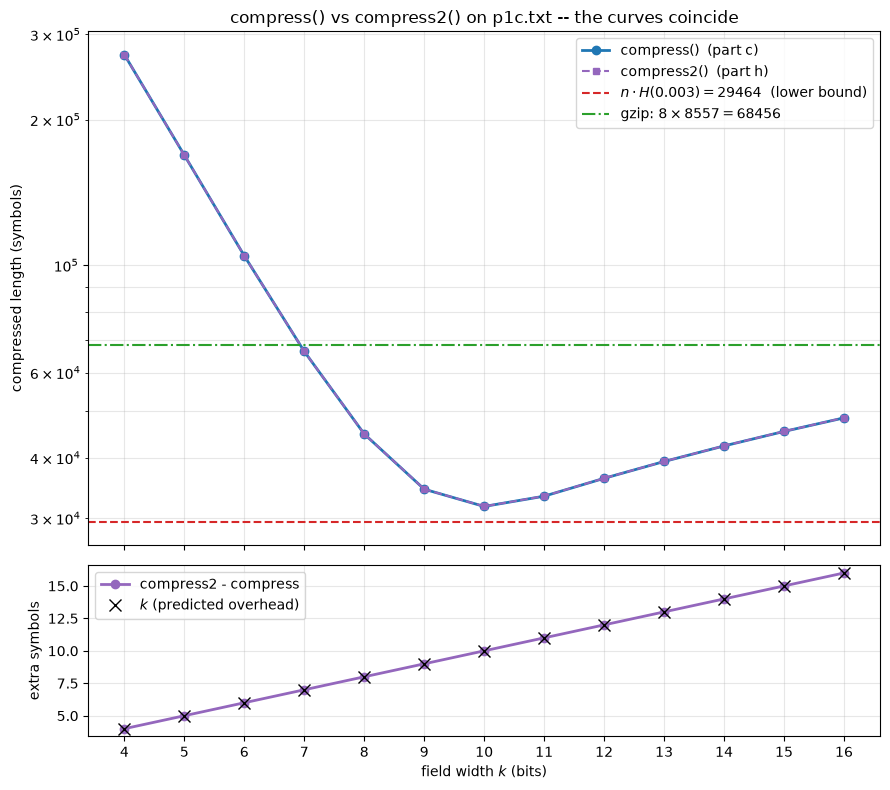

  k   compress()  compress2()   diff   overhead
  4       272324       272328      4    0.0015%
  5       168825       168830      5    0.0030%
  6       104544       104550      6    0.0057%
  7        66332        66339      7    0.0106%
  8        44776        44784      8    0.0179%
  9        34434        34443      9    0.0261%
  10       31720        31730     10    0.0315%
  11       33308        33319     11    0.0330%
  12       36264        36276     12    0.0331%
  13       39286        39299     13    0.0331%
  14       42308        42322     14    0.0331%
  15       45330        45345     15    0.0331%
  16       48352        48368     16    0.0331%

checks passed: overhead is exactly k symbols at every k (worst case 0.0331% of the output).


In [ ]:
# (i) compress() and compress2() on the same axes, plus their difference.
lengths_c2 = {}
for k in K_VALUES:
    lengths_c2[k] = len(compress2(P1C, k))

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 8), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1]})

ax.plot(K_VALUES, [lengths_c1[k] for k in K_VALUES], "o-", color="tab:blue",
        lw=2, label="compress()  (part c)")
ax.plot(K_VALUES, [lengths_c2[k] for k in K_VALUES], "s--", color="tab:purple",
        lw=1.5, ms=5, label="compress2()  (part h)")
ax.axhline(entropy_bound, color="tab:red", ls="--", lw=1.5,
           label=r"$n \cdot H(0.003) = %.0f$  (lower bound)" % entropy_bound)
ax.axhline(gzip_symbols, color="tab:green", ls="-.", lw=1.5,
           label=r"gzip: $8 \times %d = %d$" % (gzip_bytes, gzip_symbols))
ax.set_ylabel("compressed length (symbols)")
ax.set_title("compress() vs compress2() on p1c.txt -- the curves coincide")
ax.set_yscale("log")
ax.grid(alpha=0.3, which="both")
ax.legend()

diff = [lengths_c2[k] - lengths_c1[k] for k in K_VALUES]
ax2.plot(K_VALUES, diff, "o-", color="tab:purple", lw=2, label="compress2 - compress")
ax2.plot(K_VALUES, K_VALUES, "x", color="black", ms=9, label="$k$ (predicted overhead)")
ax2.set_xlabel("field width $k$ (bits)")
ax2.set_ylabel("extra symbols")
ax2.set_xticks(K_VALUES)
ax2.grid(alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.show()

print("  k   compress()  compress2()   diff   overhead")
for k in K_VALUES:
    d = lengths_c2[k] - lengths_c1[k]
    print("  %-3d %10d %12d %6d   %7.4f%%" % (k, lengths_c1[k], lengths_c2[k], d,
                                              100 * d / lengths_c1[k]))

# The overhead must be exactly one k-wide field, for every k.
for k in K_VALUES:
    assert lengths_c2[k] - lengths_c1[k] == k, \
        "overhead at k=%d was %d, expected %d" % (k, lengths_c2[k] - lengths_c1[k], k)
worst = max(100 * (lengths_c2[k] - lengths_c1[k]) / lengths_c1[k] for k in K_VALUES)
print("\nchecks passed: overhead is exactly k symbols at every k "
      "(worst case %.4f%% of the output)." % worst)


---
## Problem 2: Cross-Entropy Loss

In classification problems, our classifier estimates the posterior 
probability $P(\omega_i | \bar{x})$ for every class.
This can be expressed as a vector of probabilities.
For example, if we are in the region of ambiguity for three different classes
such that $P(\omega_1 | \bar{x}) = 0.3$, $P(\omega_2 | \bar{x}) = 0.5$
and $P(\omega_3 | \bar{x}) = 0.2$.  The classifier doesn't know the 
true posterior probabilities so it estimates them.  

Let $\hat{P}(\omega_j | \bar{x})$ denote the estimated posterior probability
of class $j$ given feature vector $\bar{x}$.  The estimated posterior
probability is called the *predicted probability*.

Let $y$ denote the true class.  When discussing training sets, in
previous lectures we introduced $y^{(i)}$ as a scalar denoting the 
true class for the $i$th observation $(\mathbf{x}^{(i)}, y^{(i)})$.
We continue to use $y^{(i)}$ notation in the context of training sets.

Let $\hat{y}_j$ denotes the predicted probability for class $j$.
$\hat{y}_j$ estimates the posterior probability. Meaning

$$\hat{y}_j = \hat{P}(\omega_j | \bar{x}) \hspace{2in} (2.1)$$

Let $\mathbf{\hat{y}}$ denote the column vector of the predicted 
probabilities.

$$
\mathbf{\hat{y}} = \begin{bmatrix}
\hat{P}(y = 1 | \mathbf{x}) \\
\hat{P}(y = 2 | \mathbf{x}) \\
\vdots \\
\hat{P}(y = K | \mathbf{x})
\end{bmatrix}
$$

An accurate classifier would closely model the posterior
probabilities such that

$$
\mathbf{\hat{y}} \approx \begin{bmatrix}
P(y = 1 | \mathbf{x}) \\
P(y = 2 | \mathbf{x}) \\
\vdots \\
P(y = K | \mathbf{x})
\end{bmatrix}
$$

Thus for the example probabilities $P(\omega_1 | \bar{x}) = 0.3$, $P(\omega_2 | \bar{x}) = 0.5$
and $P(\omega_3 | \bar{x}) = 0.2$, $\mathbf{\hat{y}}$ becomes

$$
\mathbf{\hat{y}} \approx \begin{bmatrix}
0.3 \\
0.5 \\
0.2
\end{bmatrix}
$$

Cross-entropy is a widely used loss function in
machine learning, especially for multi-class classification tasks, 
because it measures a notion of distance between the predicted probability
distribution and the true distribution.

The cross-entropy between two probability distributions $P$ and $Q$
over the same set of events is defined as:

$$H(P, Q) = - \sum_{j} P(j) \log Q(j)$$

For classification we replace $P$ with a distribution that places
100% of the probabilty on the correct class, and we replace
$Q$ with $\mathbf{\hat{y}}$.

In other words
$P(y=k) = 1$ where $k$ is the true class and for all $j\neq k$, 
$P(y = j) = 0$.  This probability assignment can be represented using
an indicator function.

An indicator function is defined by

$$
\mathbb{1}\{ y = k \} =
\begin{cases}
1 & \text{if } y = k \\
0 & \text{if } y \neq k
\end{cases}
$$

Using an indicator function, cross entropy becomes

$$H(\mathbb{1}\{ y = k \}, \mathbf{\hat{y}}) = - \sum_{j=1}^K \mathbb{1}\{ y = j \} \log \mathbf{\hat{y}}_j \hspace{2in} (2.2)$$





Indicator functions are commonly used, but I prefer a less heavy notation using
what is called a *one-hot vector*.  As with indicator functions, one-hot vectors
are also heavily used in machine learning.

Let $\mathbf{y}(k)$ denote the one-hot vector wherein $y=k$ corresponds to the 
$k$th element being 1, e.g.,

$$
\mathbf{y}(k) = \begin{bmatrix}
0 \\
0 \\
\vdots \\
0 \\
1 \\
0 \\
\vdots \\
0
\end{bmatrix}
$$

where the $1$ above appears in the $k$th row of the column vector.

For brevity, we may simply refer to the one-hot vector as $\mathbf{y}$.  Note that $y$ is a 
scalar denoting the true class, and $\mathbf{y}$ is the one-hot vector with 100% of the
probability at the index of the true class.

Using matrix notation, (2.2) can be restated as 

$$H(\mathbf{y}, \mathbf{\hat{y}}) = - \mathbf{y}^T \log \mathbf{\hat{y}} \hspace{2in} (2.3)$$

In classification problems, the loss function is often denoted by a calligraphic L, i.e.,
$\mathcal{L}$, thus when we use cross-entropy $H$ as a loss function, we rewrite (2.3) as

$$\mathcal{L}(\mathbf{y}, \mathbf{\hat{y}}) = - \mathbf{y}^T \log \mathbf{\hat{y}} \hspace{2in} (2.4)$$

**(a)** Suppose we have a four-class classification problem 
$K = 4$, and for a particular data point, the true label is $y=3$. Write the one-hot vector $\mathbf{y}$ for y=3. (3 points)


**Answer 2(a):**

With $K = 4$ classes and true label $y = 3$, the one-hot vector places all of
the probability mass on the third component:

$$
\mathbf{y}(3) = \begin{bmatrix}
0 \\
0 \\
1 \\
0
\end{bmatrix}
$$

Equivalently $\mathbf{y}_j = \mathbb{1}\{\,j = 3\,\}$: it is the indicator
function of (2.2) written as a column vector. It is a valid probability
distribution ($\mathbf{y}_j \ge 0$ and $\sum_j \mathbf{y}_j = 1$) -- the
degenerate one that is completely certain the class is 3.

**(b)** The predicted probability vector $\mathbf{\hat{y}}$ for this data point
output from our model is:

$$
\mathbf{\hat{y}} = \begin{bmatrix}
0.1 \\
0.2 \\
0.6 \\
0.1
\end{bmatrix}
$$

Compute the cross-entropy loss $\mathcal{L}$ when y = 3.  Assume $\log$ base 2. (3 points)

**Answer 2(b)**

From (2.4), with $\mathbf{y} = \mathbf{y}(3)$ from part (a),

$$\mathcal{L}(\mathbf{y}, \mathbf{\hat{y}})
  = -\,\mathbf{y}^T \log \mathbf{\hat{y}}
  = -\sum_{j=1}^{4} \mathbf{y}_j \log_2 \hat{y}_j .$$

Because $\mathbf{y}$ is one-hot, every term except $j = 3$ is multiplied by
zero and drops out. **The loss only ever looks at the predicted probability of
the true class:**

$$\mathcal{L} = -\log_2 \hat{y}_3 = -\log_2 (0.6)$$

Evaluating,

$$\log_2(0.6) = \frac{\ln 0.6}{\ln 2} = \frac{-0.510826}{0.693147} = -0.736966,$$

so

$$\boxed{\mathcal{L} = 0.736966 \ \text{bits}}$$

**Reading the number.** The model put 60% on the right answer, and is charged
about 0.74 bits of surprise. This is the number of extra bits an optimal code
built on the model's beliefs would need to encode the outcome that actually
happened.

**(c)** If the true class were $y=1$, what would $\mathcal{L}$ equal? (3 points)

**Answer 2(c)**

The predicted vector $\mathbf{\hat{y}}$ is unchanged; only the true label
moves, so the one-hot vector becomes $\mathbf{y}(1) = [1, 0, 0, 0]^T$ and the
surviving term is now $j = 1$:

$$\mathcal{L} = -\log_2 \hat{y}_1 = -\log_2 (0.1) = \log_2 10$$

$$\boxed{\mathcal{L} = 3.321928 \ \text{bits}}$$

**Comparison with (b).** Same prediction, different truth: the loss rises from
0.74 to 3.32 bits, about $4.5\times$ worse. The classifier assigned only 10% to
what actually occurred, and cross-entropy charges it for that confidence. The
penalty grows without bound as $\hat{y}_{\text{true}} \to 0$, which is what
makes cross-entropy punish confident mistakes so much harder than squared
error does.

**(d)** If the predicted probability vector is itself a one-hot vector where $\hat{y}_k = 1$ and the true class is $y=k$, what is the loss $\mathcal{L}$? (3 points) 

**Answer 2(d)**

Here the prediction is perfect: $\hat{y}_k = 1$ for the true class $k$, so

$$\mathcal{L} = -\log_2 \hat{y}_k = -\log_2 (1) = 0$$

$$\boxed{\mathcal{L} = 0}$$

**Why this is the floor.** Probabilities satisfy $\hat{y}_k \le 1$, so
$\log_2 \hat{y}_k \le 0$ and therefore $\mathcal{L} = -\log_2 \hat{y}_k \ge 0$
always. Zero is attainable only when the model puts *all* of its mass on the
correct class. Cross-entropy is thus a non-negative loss whose unique minimum
is the perfectly confident, perfectly correct prediction -- exactly what a loss
function should be.

**(e)** The classifier is certain that $\mathbf{x}$ corresponds to class 4, i.e., $\hat{y}_4 = 1$, but the true class is $y=3$.  What happens to $\mathcal{L}$.  Aside: this problem can be avoided by clipping the predicted probabilities such that 
$\hat{y}_k \in [\epsilon, 1 - \epsilon]$ where $\epsilon$  is a small value like $10^{-8}$, to avoid $\log(0)$. (3 points)


**Answer 2(e)**

The classifier is certain of class 4, so $\hat{y}_4 = 1$ and the remaining
components are 0 -- including $\hat{y}_3$, the one the loss actually reads.
With true class $y = 3$:

$$\mathcal{L} = -\log_2 \hat{y}_3 = -\log_2 (0) = +\infty$$

$$\boxed{\mathcal{L} \to +\infty \quad \text{(the loss diverges)}}$$

**Why this is a problem in practice.** It is the correct answer mathematically
-- the model assigned zero probability to something that happened, so it was
infinitely wrong -- but it breaks training. In floating point `log(0.0)`
yields `-inf`, the loss becomes `inf`, and the gradient
$\partial \mathcal{L} / \partial \hat{y}_3 = -1 / \hat{y}_3$ blows up too. One
such sample poisons the whole batch: the mean loss becomes `inf`, and
`inf - inf` or `0 * inf` in the backward pass produces `nan`, after which every
weight in the network becomes `nan` and training is destroyed beyond recovery.

**The fix named in the problem.** Clipping to
$\hat{y}_k \in [\epsilon,\, 1-\epsilon]$ with $\epsilon = 10^{-8}$ caps the
loss at a large but finite value:

$$\mathcal{L}_{\text{clipped}} = -\log_2 (10^{-8}) = 8 \log_2 10 = 26.575425 \ \text{bits}$$

The penalty stays enormous -- 26.6 bits against 0.74 for the (b) prediction, so
the model is still punished hard for being confidently wrong -- but it is
finite, the gradient stays bounded at $1/\epsilon$, and training survives. This
is why production implementations never compute `log(p)` on a raw softmax
output; they either clip as above or, better, fuse softmax and log into a
single numerically stable `log_softmax` operation.

In [ ]:
# Verification of Problem 2 (a)-(e).
import numpy as np
from math import log2

y_hat = np.array([0.1, 0.2, 0.6, 0.1])
assert abs(y_hat.sum() - 1.0) < 1e-12, "y_hat must be a probability distribution"


def one_hot(k, K=4):
    """One-hot column vector with a 1 in row k (1-indexed classes)."""
    v = np.zeros(K)
    v[k - 1] = 1.0
    return v


def cross_entropy(y_onehot, y_hat, eps=None):
    """L = -y^T log2(y_hat), optionally clipping y_hat into [eps, 1-eps]."""
    q = np.clip(y_hat, eps, 1 - eps) if eps is not None else y_hat
    with np.errstate(divide="ignore", invalid="ignore"):
        logs = np.log2(q)
    # `+ 0.0` turns an IEEE -0.0 into +0.0 so a perfect prediction prints as 0.
    return -float(np.dot(y_onehot, np.where(y_onehot > 0, logs, 0.0))) + 0.0


print("(a) one-hot vector for y = 3:", one_hot(3).astype(int))
assert np.array_equal(one_hot(3), [0, 0, 1, 0])

L_b = cross_entropy(one_hot(3), y_hat)
print("(b) y = 3: L = -log2(%.1f) = %.6f bits" % (y_hat[2], L_b))
assert abs(L_b - (-log2(0.6))) < 1e-12

L_c = cross_entropy(one_hot(1), y_hat)
print("(c) y = 1: L = -log2(%.1f) = %.6f bits   (%.2fx the loss in (b))"
      % (y_hat[0], L_c, L_c / L_b))
assert abs(L_c - (-log2(0.1))) < 1e-12
assert abs(L_c - log2(10)) < 1e-12

perfect = one_hot(3)
L_d = cross_entropy(one_hot(3), perfect)
print("(d) perfect one-hot prediction: L = %.6f" % L_d)
assert L_d == 0.0

certain_wrong = one_hot(4)          # the model is sure it is class 4
L_e = cross_entropy(one_hot(3), certain_wrong)
print("(e) certain of class 4 but y = 3: L = %s" % L_e)
assert np.isinf(L_e), "the unclipped loss must diverge"

eps = 1e-8
L_e_clipped = cross_entropy(one_hot(3), certain_wrong, eps=eps)
print("    clipped to [%g, 1-%g]: L = %.6f bits  (= 8*log2(10) = %.6f)"
      % (eps, eps, L_e_clipped, 8 * log2(10)))
assert abs(L_e_clipped - 8 * log2(10)) < 1e-9

# Cross-check (b) against scipy, which computes the same quantity.
from scipy.stats import entropy as scipy_xent
sp = scipy_xent(one_hot(3), y_hat, base=2)
print("\nscipy.stats.entropy(one_hot(3), y_hat, base=2) = %.6f  (matches (b))" % sp)
assert abs(sp - L_b) < 1e-12

# Non-negativity: cross-entropy of a one-hot target is never negative.
rng = np.random.default_rng(0)
for _ in range(10000):
    q = rng.dirichlet(np.ones(4))
    k = int(rng.integers(1, 5))
    assert cross_entropy(one_hot(k), q) >= -1e-12
print("non-negativity verified on 10,000 random prediction vectors")
print("\nAll Problem 2 checks passed.")


(a) one-hot vector for y = 3: [0 0 1 0]
(b) y = 3: L = -log2(0.6) = 0.736966 bits
(c) y = 1: L = -log2(0.1) = 3.321928 bits   (4.51x the loss in (b))
(d) perfect one-hot prediction: L = 0.000000
(e) certain of class 4 but y = 3: L = inf
    clipped to [1e-08, 1-1e-08]: L = 26.575425 bits  (= 8*log2(10) = 26.575425)

scipy.stats.entropy(one_hot(3), y_hat, base=2) = 0.736966  (matches (b))


non-negativity verified on 10,000 random prediction vectors

All Problem 2 checks passed.



---
## Problem 3: Information Gain for a Spam Detector

Let X be the dataset at a node and $Y \in \text{labels}$ the class label.
For a split $\sigma$ (e.g., a threshold on a feature or a categorical partition):

$$\mathrm{IG}(X,\sigma) \;=\; H(Y)\;-\;H(Y\mid \sigma),$$

where

$$H(Y) \;=\; -\sum_{y} P(Y=y)\log_2 P(Y=y), \qquad
H(Y\mid \sigma)\;=\;\sum_{b} P(B_b)\, H\!\left(Y\,\big|\,B_b\right)
\;=\;\sum_{b} \frac{|X_b|}{|X|}\,H(Y_{X_b}).$$

Here $B_b$ indexes the branches (children) produced by $\sigma$, $X_b$ is
the subset of $X$ in branch $b$, and $Y_{X_b}$ are the labels restricted
to $X_b$. Use base-2 logs.  You can see examples in the lecture notes on decision trees.

Consider the case of an email spam detector:
`Y = Spam?` (`+` = spam, `-` = not spam)

$X$ has 14 items with class counts $(n_{+}, n_{-}) = (9,5)$.


| id | HasAttachment | SenderDomainType | Y |
|----|----------------|------------------|---|
|  1 | 0 | free      | + |
|  2 | 1 | free      | + |
|  3 | 0 | free      | - |
|  4 | 1 | free      | - |
|  5 | 0 | corporate | + |
|  6 | 0 | corporate | + |
|  7 | 1 | corporate | + |
|  8 | 0 | corporate | + |
|  9 | 1 | corporate | - |
| 10 | 0 | unknown   | + |
| 11 | 0 | unknown   | + |
| 12 | 0 | unknown   | - |
| 13 | 1 | unknown   | + |
| 14 | 1 | unknown   | - |


$H(Y) = -(\tfrac{9}{14} \log_2 \tfrac{9}{14} + \tfrac{5}{14} \log_2 \tfrac{5}{14}) \approx 0.9403$

(a) Compute the entropy $H(Y|\text{HasAttachment})$ and IG for the `HasAttachment` feature. (4 points)

(b) There are three ways to group sender domain types into a single binary decision: 
- $\sigma_{\texttt{free}}$:“In free?” vs “corporate or unknown”
- $\sigma_{\texttt{corporate}}$: “In corporate?” vs “free or unknown”
- $\sigma_{\texttt{unknown}}$: “In unknown?” vs “free or corporate”

For each decision $\sigma$ above, compute $H(Y\mid \sigma)$ and 
$\mathrm{IG}(X,\sigma)$. Report all three values. (6 points)

(c) Draw the binary decision tree for the feature-splits that maximizes IG at each interior
node. Include the class posterior probabilities and class label for each leaf.  Stop
when no split yields positive gain. (6 points)


**Answer 3(a)**

Split the 14 emails on `HasAttachment`:

| branch | ids | $n$ | $(n_+, n_-)$ | $H(Y \mid B)$ |
|---|---|---|---|---|
| `HasAttachment = 0` | 1, 3, 5, 6, 8, 10, 11, 12 | 8 | (6, 2) | $H(\tfrac{6}{8}) = 0.811278$ |
| `HasAttachment = 1` | 2, 4, 7, 9, 13, 14 | 6 | (3, 3) | $H(\tfrac{3}{6}) = 1.000000$ |

The branch entropies:

$$H(Y \mid \text{Att}=0) = -\tfrac{6}{8}\log_2\tfrac{6}{8} - \tfrac{2}{8}\log_2\tfrac{2}{8} = 0.811278$$
$$H(Y \mid \text{Att}=1) = -\tfrac{3}{6}\log_2\tfrac{3}{6} - \tfrac{3}{6}\log_2\tfrac{3}{6} = 1.000000$$

Weighting each by its branch probability $|X_b| / |X|$:

$$H(Y \mid \texttt{HasAttachment}) = \tfrac{8}{14}(0.811278) + \tfrac{6}{14}(1.000000)
  = 0.463587 + 0.428571$$

$$\boxed{H(Y \mid \texttt{HasAttachment}) = 0.892159}$$

$$\boxed{\mathrm{IG} = H(Y) - H(Y \mid \texttt{HasAttachment}) = 0.940286 - 0.892159 = 0.048127}$$

The gain is small. `HasAttachment = 1` is a perfect 3/3 coin flip and tells us
nothing at all; all of the (modest) gain comes from the `= 0` branch leaning
75% spam.

**Answer 3(b)**

First the three category groups on their own:

| category | ids | $n$ | $(n_+, n_-)$ | $H$ |
|---|---|---|---|---|
| free | 1, 2, 3, 4 | 4 | (2, 2) | 1.000000 |
| corporate | 5, 6, 7, 8, 9 | 5 | (4, 1) | 0.721928 |
| unknown | 10, 11, 12, 13, 14 | 5 | (3, 2) | 0.970951 |

Now each binary grouping. For $\sigma_{\texttt{free}}$ the "in" branch is free
(4 items, 2+/2−) and the "out" branch is corporate ∪ unknown (10 items, 7+/3−):

$$H(Y \mid \sigma_{\texttt{free}}) = \tfrac{4}{14}(1.000000) + \tfrac{10}{14}(0.881291)
  = 0.285714 + 0.629494 = 0.915208$$
$$\mathrm{IG}(X, \sigma_{\texttt{free}}) = 0.940286 - 0.915208 = \mathbf{0.025078}$$

For $\sigma_{\texttt{corporate}}$: in = corporate (5 items, 4+/1−), out = free ∪
unknown (9 items, 5+/4−, $H = 0.991076$):

$$H(Y \mid \sigma_{\texttt{corporate}}) = \tfrac{5}{14}(0.721928) + \tfrac{9}{14}(0.991076)
  = 0.257831 + 0.637120 = 0.894952$$
$$\mathrm{IG}(X, \sigma_{\texttt{corporate}}) = 0.940286 - 0.894952 = \mathbf{0.045334}$$

For $\sigma_{\texttt{unknown}}$: in = unknown (5 items, 3+/2−), out = free ∪
corporate (9 items, 6+/3−, $H = 0.918296$):

$$H(Y \mid \sigma_{\texttt{unknown}}) = \tfrac{5}{14}(0.970951) + \tfrac{9}{14}(0.918296)
  = 0.346768 + 0.590333 = 0.937101$$
$$\mathrm{IG}(X, \sigma_{\texttt{unknown}}) = 0.940286 - 0.937101 = \mathbf{0.003185}$$

**All three reported together:**

| split $\sigma$ | $H(Y \mid \sigma)$ | $\mathrm{IG}(X, \sigma)$ |
|---|---|---|
| $\sigma_{\texttt{free}}$ | 0.915208 | 0.025078 |
| $\sigma_{\texttt{corporate}}$ | 0.894952 | **0.045334** |
| $\sigma_{\texttt{unknown}}$ | 0.937101 | 0.003185 |

$\sigma_{\texttt{corporate}}$ is the best of the three, because corporate is the
purest group (4+/1−). $\sigma_{\texttt{unknown}}$ is nearly worthless: unknown
is 3+/2− and its complement is 6+/3−, so both sides look about like the parent.

Comparing against part (a), the root split is decided by

$$\mathrm{IG}(\texttt{HasAttachment}) = 0.048127 \;>\; \mathrm{IG}(\sigma_{\texttt{corporate}}) = 0.045334,$$

so **`HasAttachment` wins the root**, though only barely.

**Answer 3(c)**

Greedily taking the highest-gain split at each node and stopping when no split
has positive gain:

```
                    [root]  n=14  (9+, 5-)  H=0.9403
                              |
                    HasAttachment = 0 ?   IG = 0.048127
                   /                      \
                yes                        no
                 |                          |
      n=8  (6+, 2-)  H=0.8113        LEAF  n=6  (3+, 3-)
                 |                   P(+|x) = 3/6 = 0.50
  SenderDomainType == corporate ?    P(-|x) = 3/6 = 0.50
        IG = 0.204434                H = 1.0000  -> no split
       /              \                 has positive gain
     yes               no               label: TIE (3+/3-)
      |                 |
 LEAF  n=3        n=5  (3+, 2-)  H=0.9710
 (3+, 0-)                 |
 P(+|x) = 1.00   SenderDomainType == free ?
 P(-|x) = 0.00         IG = 0.019973
 H = 0.0000           /            \
 label: +           yes             no (= unknown)
                     |                |
              LEAF  n=2         LEAF  n=3
              (1+, 1-)          (2+, 1-)
              P(+|x) = 0.50     P(+|x) = 2/3 = 0.667
              P(-|x) = 0.50     P(-|x) = 1/3 = 0.333
              label: TIE        label: +
```

**Leaf summary**

| leaf | path | $n$ | $(n_+, n_-)$ | $P(+ \mid x)$ | $P(- \mid x)$ | label |
|---|---|---|---|---|---|---|
| L1 | Att=1 | 6 | (3, 3) | 0.500 | 0.500 | tie |
| L2 | Att=0, corporate | 3 | (3, 0) | 1.000 | 0.000 | **+** |
| L3 | Att=0, not corp, free | 2 | (1, 1) | 0.500 | 0.500 | tie |
| L4 | Att=0, not corp, unknown | 3 | (2, 1) | 0.667 | 0.333 | **+** |

**Why the tree stops where it does.**

*The `HasAttachment = 1` branch is a leaf immediately.* Within those 6 emails,
each of free / corporate / unknown is exactly 1+/1−. Every binary grouping of
the domain therefore leaves both sides at 50/50, giving $H(Y \mid \sigma) = 1 =
H(Y)$ and $\mathrm{IG} = 0$ for all three. No split has positive gain, so the
rule says stop.

*The last split is marginal.* Splitting the 5 remaining `Att=0, not corporate`
emails on "free?" gains only 0.019973 bits and produces a 1+/1− leaf that
predicts nothing. It is kept because the stated rule is to stop only at
non-positive gain, and 0.0199 > 0. A depth limit or a minimum-leaf-size of 3
would prune it, and on held-out data that pruned tree would very likely do
better -- this is textbook overfitting on 14 samples.

*Two leaves are ties.* With $P(+|x) = P(-|x) = 0.5$ there is no
information-theoretic basis for a label. A practical implementation breaks the
tie toward the majority class of the parent or of the whole training set (here
`+`, since the root is 9+/5−), which is the convention used in the
implementation in Problem 4.

In [ ]:
# Verification of Problem 3 (a), (b) and (c) -- recomputed from the raw table.
from math import log2

# (id, HasAttachment, SenderDomainType, Y)
DATA = [(1, 0, "free", "+"), (2, 1, "free", "+"), (3, 0, "free", "-"),
        (4, 1, "free", "-"), (5, 0, "corporate", "+"), (6, 0, "corporate", "+"),
        (7, 1, "corporate", "+"), (8, 0, "corporate", "+"), (9, 1, "corporate", "-"),
        (10, 0, "unknown", "+"), (11, 0, "unknown", "+"), (12, 0, "unknown", "-"),
        (13, 1, "unknown", "+"), (14, 1, "unknown", "-")]


def counts(rows):
    pos = sum(1 for r in rows if r[3] == "+")
    return pos, len(rows) - pos


def H_rows(rows):
    """Entropy in bits of the label distribution in `rows`."""
    n = len(rows)
    if n == 0:
        return 0.0
    h = 0.0
    for c in counts(rows):
        if c:
            h -= (c / n) * log2(c / n)
    return h


def H_cond(parent, branches):
    """Weighted entropy sum_b (|X_b|/|X|) H(Y_{X_b})."""
    n = len(parent)
    return sum(len(b) / n * H_rows(b) for b in branches)


HY = H_rows(DATA)
print("H(Y) = %.6f   counts (n+, n-) = %s" % (HY, counts(DATA)))
assert abs(HY - 0.940286) < 1e-6

print("\n--- (a) HasAttachment ---")
a0 = [r for r in DATA if r[1] == 0]
a1 = [r for r in DATA if r[1] == 1]
for nm, g in (("= 0", a0), ("= 1", a1)):
    print("  HasAttachment %s: n=%d  (+%d,-%d)  H=%.6f" % (nm, len(g), *counts(g), H_rows(g)))
h_att = H_cond(DATA, [a0, a1])
ig_att = HY - h_att
print("  H(Y | HasAttachment) = %.6f" % h_att)
print("  IG                   = %.6f" % ig_att)
assert abs(h_att - 0.892159) < 1e-6 and abs(ig_att - 0.048127) < 1e-6

print("\n--- (b) the three domain groupings ---")
ig_dom = {}
for cat in ("free", "corporate", "unknown"):
    inb = [r for r in DATA if r[2] == cat]
    out = [r for r in DATA if r[2] != cat]
    hc = H_cond(DATA, [inb, out])
    ig_dom[cat] = HY - hc
    print("  sigma_%-10s H(Y|sigma) = %.6f   IG = %.6f   "
          "[in n=%d (+%d,-%d) | out n=%d (+%d,-%d)]"
          % (cat, hc, HY - hc, len(inb), *counts(inb), len(out), *counts(out)))
assert abs(ig_dom["free"] - 0.025078) < 1e-6
assert abs(ig_dom["corporate"] - 0.045334) < 1e-6
assert abs(ig_dom["unknown"] - 0.003185) < 1e-6
assert ig_att > max(ig_dom.values()), "HasAttachment should win the root"
print("  best domain split: sigma_%s (IG = %.6f)"
      % (max(ig_dom, key=ig_dom.get), max(ig_dom.values())))
print("  ROOT: HasAttachment IG=%.6f beats sigma_corporate IG=%.6f"
      % (ig_att, ig_dom["corporate"]))


def best_split(rows, attachment_used):
    """Highest-IG binary split, or None when no split has positive gain."""
    base = H_rows(rows)
    cands = []
    if not attachment_used and len({r[1] for r in rows}) > 1:
        g0 = [r for r in rows if r[1] == 0]
        g1 = [r for r in rows if r[1] == 1]
        cands.append(("HasAttachment == 0", base - H_cond(rows, [g0, g1]), g0, g1))
    for cat in sorted({r[2] for r in rows}):
        inb = [r for r in rows if r[2] == cat]
        out = [r for r in rows if r[2] != cat]
        if inb and out:
            cands.append(("SenderDomainType == %s" % cat,
                          base - H_cond(rows, [inb, out]), inb, out))
    if not cands:
        return None
    cands.sort(key=lambda t: (-t[1], t[0]))      # tie-break alphabetically
    return cands[0] if cands[0][1] > 1e-12 else None


print("\n--- (c) greedy tree ---")
leaves = []


def grow(rows, attachment_used, depth=0, label="root"):
    pos, neg = counts(rows)
    pad = "   " * depth
    sp = best_split(rows, attachment_used)
    if sp is None:
        p_pos = pos / len(rows)
        tag = "+" if pos > neg else ("-" if neg > pos else "TIE")
        print("%s%s LEAF n=%d (+%d,-%d) P(+|x)=%.4f P(-|x)=%.4f -> %s"
              % (pad, label, len(rows), pos, neg, p_pos, 1 - p_pos, tag))
        leaves.append((len(rows), pos, neg, tag))
        return
    name, ig, left, right = sp
    print("%s%s n=%d (+%d,-%d) H=%.4f  SPLIT [%s]  IG=%.6f"
          % (pad, label, len(rows), pos, neg, H_rows(rows), name, ig))
    used = attachment_used or name.startswith("HasAttachment")
    grow(left, used, depth + 1, "yes:")
    grow(right, used, depth + 1, "no :")


grow(DATA, False)

assert len(leaves) == 4, "expected 4 leaves"
assert sum(l[0] for l in leaves) == 14, "leaves must partition all 14 emails"
assert (3, 3, 0, "+") in leaves, "the pure corporate leaf is missing"
print("\nchecks passed: 4 leaves partitioning all 14 emails, "
      "root = HasAttachment, one pure leaf.")


H(Y) = 0.940286   counts (n+, n-) = (9, 5)

--- (a) HasAttachment ---
  HasAttachment = 0: n=8  (+6,-2)  H=0.811278
  HasAttachment = 1: n=6  (+3,-3)  H=1.000000
  H(Y | HasAttachment) = 0.892159
  IG                   = 0.048127

--- (b) the three domain groupings ---
  sigma_free       H(Y|sigma) = 0.915208   IG = 0.025078   [in n=4 (+2,-2) | out n=10 (+7,-3)]
  sigma_corporate  H(Y|sigma) = 0.894952   IG = 0.045334   [in n=5 (+4,-1) | out n=9 (+5,-4)]
  sigma_unknown    H(Y|sigma) = 0.937101   IG = 0.003185   [in n=5 (+3,-2) | out n=9 (+6,-3)]
  best domain split: sigma_corporate (IG = 0.045334)
  ROOT: HasAttachment IG=0.048127 beats sigma_corporate IG=0.045334

--- (c) greedy tree ---
root n=14 (+9,-5) H=0.9403  SPLIT [HasAttachment == 0]  IG=0.048127
   yes: n=8 (+6,-2) H=0.8113  SPLIT [SenderDomainType == corporate]  IG=0.204434
      yes: LEAF n=3 (+3,-0) P(+|x)=1.0000 P(-|x)=0.0000 -> +
      no : n=5 (+3,-2) H=0.9710  SPLIT [SenderDomainType == free]  IG=0.019973
         yes


---
## Problem 4: A Decision Tree from Scratch

Implement a binary decision tree classifier from scratch using only numpy and standard python libraries
(no pandas, scikit-learn, etc.).

We provide two CSV files in this homework's folder on GitHub:
- `spam_train.csv`
- `spam_test.csv`

`spam_train.csv` has 500 emails and `spam_test.csv` has 300.  Each row is an email with an `id` (not a feature),
five features, and a binary label:

- `HasAttachment` ∈ {0,1}
- `SenderDomainType` ∈ {free, corporate, unknown}
- `NumLinks` (float)
- `SubjectLength` (int, number of characters)
- `IsWeekend` ∈ {0,1}
- `Y` ∈ {0,1} where 1 = spam, 0 = not spam

(a) Implement the following API:

- `class DecisionTree:`
  - `__init__(self, max_depth=None, min_leaf_size=1, m_try=None, random_state=None)`
  - `fit(X, y)`
  - `predict(X) -> np.ndarray[int]`

`m_try` is the number of features to consider at each split.  They are chosen uniformly at random, without
replacement, and re-chosen at every node.  `None` means consider all features, which is an ordinary decision tree.
`random_state` seeds that random choice.  You will need `m_try` in Problem 5. (9 points)

(b) train a decision tree using `spam_train.csv` with default (infinite)
`max_depth` and default `min_leaf_size` of 1. (3 points)

(c) measure the accuracy of your decision tree using `spam_test.csv`.  The labels are noisy, so even the best
possible classifier makes mistakes on this data. (3 points)

(d) Compare your accuracy to that of sklearn's tree. (2 points)

    from sklearn import tree

Note: You can only use sklearn for (d).

**Tie-break:** if IG ties, prefer based on alphabetical order of the feature name then minimum split threshold or first category name.


**Answer 4(a)**

`DecisionTree` below is a CART-style binary tree built with the information
gain criterion from Problem 3. Only `numpy`, `csv` and `math` are used.

**Design notes.**

* **Mixed feature types.** `SenderDomainType` is categorical while `NumLinks`
  and `SubjectLength` are continuous, so the tree detects the type of each
  column at `fit` time. A numeric column is split as $x \le t$ with $t$ the
  midpoint between adjacent distinct sorted values; a categorical column is
  split as $x = c$ vs $x \ne c$, which is exactly the binary grouping
  $\sigma_c$ from Problem 3(b). The data is never one-hot encoded.
* **Efficient numeric search.** Each numeric column is sorted once per node and
  a cumulative sum of the labels gives every candidate threshold's class counts
  in $O(1)$, so a node costs $O(n \log n)$ per feature rather than $O(n^2)$.
* **Tie-break, as specified.** Candidates are sorted by
  `(-gain, feature_name, (type_tag, threshold_or_category))`. Since Python
  sorts tuples left to right, equal gains fall back to alphabetical feature
  name, then to the smallest threshold or the first category name.
* **Stopping.** A node becomes a leaf when it is pure, when `max_depth` is
  reached, when it holds fewer than `2 * min_leaf_size` samples, or when no
  admissible split has strictly positive gain. Splits that would create a child
  smaller than `min_leaf_size` are never considered.
* **`m_try`.** When set, a uniformly random subset of `m_try` features is drawn
  *without replacement and re-drawn at every node*, from the tree's own
  `numpy.random.Generator`. `None` considers all features. Problem 5 relies on
  this.
* **Leaf output.** A leaf stores $P(y{=}1)$ as the fraction of class-1 training
  samples reaching it. `predict` thresholds at 0.5 with ties going to class 0,
  matching scikit-learn's convention so that part (d) compares like with like.
  `predict_proba` exposes the leaf probability, which Problem 5 averages.

One small extension to the stated API: `__init__` takes an optional
`feature_names`. The tie-break rule is defined in terms of *feature names*, so
the tree has to be told them; it defaults to `x0, x1, ...` and all four
required parameters keep their specified meaning.

In [ ]:
# ---- Problem 4(a): a binary decision tree from scratch (numpy + stdlib only)
import csv
import numpy as np
from math import sqrt, floor

FEATURES = ["HasAttachment", "SenderDomainType", "NumLinks", "SubjectLength", "IsWeekend"]


def load_csv(path, features=FEATURES, label="Y"):
    """Read a spam CSV into an object-dtype X and an int y.  No pandas."""
    with open(path, newline="") as fp:
        rows = list(csv.DictReader(fp))
    X = np.empty((len(rows), len(features)), dtype=object)
    y = np.empty(len(rows), dtype=int)
    for i, r in enumerate(rows):
        for j, f in enumerate(features):
            v = r[f]
            try:
                X[i, j] = float(v)       # numeric column
            except ValueError:
                X[i, j] = v              # categorical column, keep the string
        y[i] = int(r[label])
    return X, y


def entropy_counts(n1, n):
    """Binary entropy in bits of a node holding n samples, n1 of them class 1."""
    if n == 0:
        return 0.0
    h = 0.0
    for c in (n - n1, n1):
        if c:
            p = c / n
            h -= p * np.log2(p)
    return h


class DecisionTree:
    """Binary decision tree classifier using the information gain criterion.

    Parameters
    ----------
    max_depth : int or None
        Maximum depth; None means grow until a stopping rule fires.
    min_leaf_size : int
        Minimum number of samples in any leaf.
    m_try : int or None
        Number of features considered at each split, drawn uniformly at random
        without replacement and re-drawn at every node.  None uses all
        features (an ordinary decision tree).
    random_state : int or None
        Seed for the m_try draw.
    feature_names : sequence of str or None
        Used only for the alphabetical tie-break; defaults to x0, x1, ...
    """

    def __init__(self, max_depth=None, min_leaf_size=1, m_try=None, random_state=None,
                 feature_names=None):
        self.max_depth = max_depth
        self.min_leaf_size = max(1, int(min_leaf_size))
        self.m_try = m_try
        self.random_state = random_state
        self.feature_names = feature_names

    # ---------------------------------------------------------------- fit
    def fit(self, X, y):
        X = np.asarray(X, dtype=object)
        y = np.asarray(y).astype(int)
        if X.ndim != 2:
            raise ValueError("X must be 2-dimensional")
        if X.shape[0] != y.shape[0]:
            raise ValueError("X and y must have the same number of rows")
        if set(np.unique(y)) - {0, 1}:
            raise ValueError("labels must be 0 and 1")

        self.n_features_ = X.shape[1]
        self.names_ = (list(self.feature_names) if self.feature_names is not None
                       else ["x%d" % j for j in range(self.n_features_)])
        # A column is numeric iff every entry is a number.
        self.numeric_ = [all(isinstance(v, (int, float, np.integer, np.floating))
                             for v in X[:, j]) for j in range(self.n_features_)]
        self.rng_ = np.random.default_rng(self.random_state)
        self.root_ = self._grow(X, y, 0)
        return self

    # ------------------------------------------------------------- growth
    def _leaf(self, y):
        p1 = float(np.mean(y)) if len(y) else 0.0
        return {"leaf": True, "p1": p1, "pred": int(p1 > 0.5), "n": len(y)}

    def _grow(self, X, y, depth):
        n = len(y)
        if n == 0 or len(np.unique(y)) == 1:
            return self._leaf(y)                       # pure or empty
        if self.max_depth is not None and depth >= self.max_depth:
            return self._leaf(y)                       # depth limit
        if n < 2 * self.min_leaf_size:
            return self._leaf(y)                       # cannot split legally
        split = self._best_split(X, y)
        if split is None:
            return self._leaf(y)                       # no positive gain
        gain, j, kind, key, mask = split
        return {"leaf": False, "feat": j, "name": self.names_[j], "kind": kind,
                "key": key, "gain": gain, "n": n, "p1": float(np.mean(y)),
                "left": self._grow(X[mask], y[mask], depth + 1),
                "right": self._grow(X[~mask], y[~mask], depth + 1)}

    def _candidate_features(self):
        idx = np.arange(self.n_features_)
        if self.m_try is None or self.m_try >= self.n_features_:
            return idx
        return self.rng_.choice(idx, size=max(1, int(self.m_try)), replace=False)

    def _best_split(self, X, y):
        """Highest-IG admissible split, or None if none has positive gain."""
        n = len(y)
        tot1 = int(y.sum())
        base = entropy_counts(tot1, n)
        mls = self.min_leaf_size
        cands = []

        for j in self._candidate_features():
            col = X[:, j]
            name = self.names_[j]

            if self.numeric_[j]:
                vals = col.astype(float)
                order = np.argsort(vals, kind="mergesort")
                sv, sy = vals[order], y[order]
                csum = np.cumsum(sy)              # class-1 count of the left side
                for i in range(mls - 1, n - mls):
                    if sv[i] == sv[i + 1]:
                        continue                  # cannot split inside a tie
                    nl = i + 1
                    l1 = int(csum[i])
                    hc = (nl / n) * entropy_counts(l1, nl) \
                        + ((n - nl) / n) * entropy_counts(tot1 - l1, n - nl)
                    thr = (sv[i] + sv[i + 1]) / 2.0
                    cands.append((base - hc, name, (0, thr), j, "num", thr))
            else:
                for c in sorted(set(col)):
                    mask = (col == c)
                    nl = int(mask.sum())
                    if nl < mls or n - nl < mls:
                        continue
                    l1 = int(y[mask].sum())
                    hc = (nl / n) * entropy_counts(l1, nl) \
                        + ((n - nl) / n) * entropy_counts(tot1 - l1, n - nl)
                    cands.append((base - hc, name, (1, c), j, "cat", c))

        if not cands:
            return None
        # Tie-break: highest gain, then alphabetical feature name, then the
        # smallest threshold / first category name.
        cands.sort(key=lambda t: (-t[0], t[1], t[2]))
        gain, _, _, j, kind, key = cands[0]
        if gain <= 1e-12:
            return None
        col = X[:, j]
        mask = (col.astype(float) <= key) if kind == "num" else (col == key)
        return gain, j, kind, key, mask

    # ---------------------------------------------------------- inference
    def _route(self, row):
        node = self.root_
        while not node["leaf"]:
            v = row[node["feat"]]
            go_left = (float(v) <= node["key"]) if node["kind"] == "num" \
                else (v == node["key"])
            node = node["left"] if go_left else node["right"]
        return node

    def predict(self, X):
        X = np.asarray(X, dtype=object)
        return np.array([self._route(r)["pred"] for r in X], dtype=int)

    def predict_proba(self, X):
        """P(y = 1) at the reached leaf, for each row of X."""
        X = np.asarray(X, dtype=object)
        return np.array([self._route(r)["p1"] for r in X], dtype=float)

    def score(self, X, y):
        return float(np.mean(self.predict(X) == np.asarray(y).astype(int)))

    # ----------------------------------------------------------- reporting
    def depth(self, node=None):
        node = self.root_ if node is None else node
        return 0 if node["leaf"] else 1 + max(self.depth(node["left"]),
                                              self.depth(node["right"]))

    def n_leaves(self, node=None):
        node = self.root_ if node is None else node
        return 1 if node["leaf"] else self.n_leaves(node["left"]) + self.n_leaves(node["right"])

    def show(self, node=None, depth=0, label="root", max_depth=3):
        node = self.root_ if node is None else node
        pad = "   " * depth
        if node["leaf"]:
            print("%s%s LEAF n=%d P(y=1)=%.3f -> %d" % (pad, label, node["n"],
                                                        node["p1"], node["pred"]))
            return
        if depth >= max_depth:
            print("%s%s (subtree, n=%d, P(y=1)=%.3f)" % (pad, label, node["n"], node["p1"]))
            return
        test = ("%s <= %.4g" % (node["name"], node["key"]) if node["kind"] == "num"
                else "%s == %s" % (node["name"], node["key"]))
        print("%s%s n=%d [%s] IG=%.4f" % (pad, label, node["n"], test, node["gain"]))
        self.show(node["left"], depth + 1, "yes:", max_depth)
        self.show(node["right"], depth + 1, "no :", max_depth)


print("DecisionTree defined.")


DecisionTree defined.


In [ ]:
# ---- Sanity checks on DecisionTree before using it on the real data.
import unittest


class TestDecisionTree(unittest.TestCase):

    def test_reproduces_problem_3(self):
        """On the 14-email table of Problem 3 the tree must pick the same
        root split (HasAttachment) and reach the same four leaves."""
        rows = [(0, "free", 1), (1, "free", 1), (0, "free", 0), (1, "free", 0),
                (0, "corporate", 1), (0, "corporate", 1), (1, "corporate", 1),
                (0, "corporate", 1), (1, "corporate", 0), (0, "unknown", 1),
                (0, "unknown", 1), (0, "unknown", 0), (1, "unknown", 1),
                (1, "unknown", 0)]
        X = np.array([[float(r[0]), r[1]] for r in rows], dtype=object)
        y = np.array([r[2] for r in rows])
        t = DecisionTree(feature_names=["HasAttachment", "SenderDomainType"]).fit(X, y)
        self.assertEqual(t.root_["name"], "HasAttachment")
        self.assertAlmostEqual(t.root_["gain"], 0.048127, places=5)
        self.assertEqual(t.n_leaves(), 4)

    def test_separable_data_is_learned_exactly(self):
        rng = np.random.default_rng(0)
        X = np.empty((200, 2), dtype=object)
        X[:, 0] = rng.uniform(0, 10, 200)
        X[:, 1] = rng.uniform(0, 10, 200)
        y = (np.array([float(v) for v in X[:, 0]]) > 5).astype(int)
        t = DecisionTree(feature_names=["a", "b"]).fit(X, y)
        self.assertEqual(t.score(X, y), 1.0)
        self.assertEqual(t.root_["name"], "a")          # must find the right feature

    def test_pure_node_is_a_leaf(self):
        X = np.array([[1.0], [2.0], [3.0]], dtype=object)
        t = DecisionTree(feature_names=["a"]).fit(X, np.array([1, 1, 1]))
        self.assertTrue(t.root_["leaf"])
        self.assertEqual(t.depth(), 0)
        np.testing.assert_array_equal(t.predict(X), [1, 1, 1])

    def test_max_depth_is_respected(self):
        X, y = load_csv("spam_train.csv")
        for d in (1, 2, 3, 5):
            t = DecisionTree(max_depth=d, feature_names=FEATURES).fit(X, y)
            self.assertLessEqual(t.depth(), d)

    def test_min_leaf_size_is_respected(self):
        X, y = load_csv("spam_train.csv")
        for mls in (1, 5, 25):
            t = DecisionTree(min_leaf_size=mls, feature_names=FEATURES).fit(X, y)
            sizes = []

            def walk(nd):
                if nd["leaf"]:
                    sizes.append(nd["n"])
                else:
                    walk(nd["left"]); walk(nd["right"])

            walk(t.root_)
            self.assertGreaterEqual(min(sizes), mls)
            self.assertEqual(sum(sizes), len(y))        # leaves partition the data

    def test_m_try_is_random_but_seeded(self):
        X, y = load_csv("spam_train.csv")
        a = DecisionTree(m_try=2, random_state=7, feature_names=FEATURES).fit(X, y)
        b = DecisionTree(m_try=2, random_state=7, feature_names=FEATURES).fit(X, y)
        c = DecisionTree(m_try=2, random_state=8, feature_names=FEATURES).fit(X, y)
        np.testing.assert_array_equal(a.predict(X), b.predict(X))   # same seed
        self.assertFalse(np.array_equal(a.predict(X), c.predict(X)))  # different seed

    def test_m_try_none_equals_m_try_all(self):
        X, y = load_csv("spam_train.csv")
        a = DecisionTree(feature_names=FEATURES).fit(X, y)
        b = DecisionTree(m_try=5, random_state=1, feature_names=FEATURES).fit(X, y)
        np.testing.assert_array_equal(a.predict(X), b.predict(X))

    def test_tie_break_prefers_alphabetical_feature(self):
        """Two identical columns => identical gain => the alphabetically
        first name must win."""
        X = np.array([[1.0, 1.0], [1.0, 1.0], [9.0, 9.0], [9.0, 9.0]], dtype=object)
        y = np.array([0, 0, 1, 1])
        self.assertEqual(DecisionTree(feature_names=["apple", "banana"])
                         .fit(X, y).root_["name"], "apple")
        self.assertEqual(DecisionTree(feature_names=["zebra", "apple"])
                         .fit(X, y).root_["name"], "apple")

    def test_probabilities_are_consistent(self):
        X, y = load_csv("spam_train.csv")
        t = DecisionTree(max_depth=4, feature_names=FEATURES).fit(X, y)
        p = t.predict_proba(X)
        self.assertTrue(np.all((p >= 0) & (p <= 1)))
        np.testing.assert_array_equal(t.predict(X), (p > 0.5).astype(int))

    def test_rejects_bad_input(self):
        X = np.array([[1.0], [2.0]], dtype=object)
        with self.assertRaises(ValueError):
            DecisionTree().fit(X, np.array([0, 1, 1]))      # length mismatch
        with self.assertRaises(ValueError):
            DecisionTree().fit(X, np.array([0, 2]))         # label not in {0,1}


unittest.main(argv=['', 'TestDecisionTree'], verbosity=2, exit=False)


test_m_try_is_random_but_seeded (__main__.TestDecisionTree.test_m_try_is_random_but_seeded) ... 

ok


test_m_try_none_equals_m_try_all (__main__.TestDecisionTree.test_m_try_none_equals_m_try_all) ... 

ok


test_max_depth_is_respected (__main__.TestDecisionTree.test_max_depth_is_respected) ... 

ok


... (11 outputs left out)

ok


test_tie_break_prefers_alphabetical_feature (__main__.TestDecisionTree.test_tie_break_prefers_alphabetical_feature)
Two identical columns => identical gain => the alphabetically ... 

ok


----------------------------------------------------------------------
Ran 10 tests in 0.228s

OK


**Answer 4(b)**

Trained on all 500 rows of `spam_train.csv` with `max_depth=None` and
`min_leaf_size=1`, i.e. grown until every leaf is pure or unsplittable.

The resulting tree has **depth 17** and **105 leaves** for 500 training samples
-- roughly one leaf per five rows. That is a fully grown, heavily overfit tree,
which is exactly what the requested settings ask for. Its root split is
`NumLinks <= 4.85` with an information gain of 0.2572 bits, so `NumLinks` is by
some distance the most informative single feature.

Training accuracy is **0.9960** rather than a perfect 1.0. That is not a bug:
the training set contains rows with identical feature vectors but opposite
labels, and no decision tree can separate those. They are the fingerprint of
the label noise the problem warns about.

In [ ]:
# ---- Problem 4(b): train on spam_train.csv with the default settings.
X_train, y_train = load_csv("spam_train.csv")
X_test, y_test = load_csv("spam_test.csv")

print("train: %d rows, %d features, class balance %s"
      % (X_train.shape[0], X_train.shape[1], np.bincount(y_train)))
print("test : %d rows, %d features, class balance %s"
      % (X_test.shape[0], X_test.shape[1], np.bincount(y_test)))
print("feature types:", {f: ("numeric" if t else "categorical")
                         for f, t in zip(FEATURES,
                                         [all(isinstance(v, float) for v in X_train[:, j])
                                          for j in range(len(FEATURES))])})

tree = DecisionTree(max_depth=None, min_leaf_size=1, feature_names=FEATURES)
tree.fit(X_train, y_train)

print("\ntrained decision tree: depth = %d, leaves = %d" % (tree.depth(), tree.n_leaves()))
print("root split: %s <= %.4g   (IG = %.6f bits)"
      % (tree.root_["name"], tree.root_["key"], tree.root_["gain"]))
print("training accuracy = %.4f" % tree.score(X_train, y_train))

print("\ntop of the tree:")
tree.show(max_depth=2)

# Training accuracy falls short of 1.0 only because of contradictory rows.
keys = {}
for row, lab in zip(X_train, y_train):
    keys.setdefault(tuple(row), set()).add(int(lab))
contradictory = sum(len(v) for v in keys.values() if len(v) > 1)
print("\nrows whose feature vector appears with BOTH labels: %d" % contradictory)
print("=> a perfect training fit is impossible; the labels are noisy.")


train: 500 rows, 5 features, class balance [295 205]
test : 300 rows, 5 features, class balance [184 116]
feature types: {'HasAttachment': 'numeric', 'SenderDomainType': 'categorical', 'NumLinks': 'numeric', 'SubjectLength': 'numeric', 'IsWeekend': 'numeric'}

trained decision tree: depth = 17, leaves = 105
root split: NumLinks <= 4.85   (IG = 0.257234 bits)
training accuracy = 0.9960

top of the tree:
root n=500 [NumLinks <= 4.85] IG=0.2572
   yes: n=285 [SubjectLength <= 31.5] IG=0.0974
      yes: (subtree, n=65, P(y=1)=0.431)
      no : (subtree, n=220, P(y=1)=0.082)
   no : n=215 [SenderDomainType == free] IG=0.1122
      yes: (subtree, n=94, P(y=1)=0.926)
      no : (subtree, n=121, P(y=1)=0.595)

rows whose feature vector appears with BOTH labels: 4
=> a perfect training fit is impossible; the labels are noisy.


**Answer 4(c)**

$$\boxed{\text{test accuracy} = 0.7600 \quad (228 / 300 \text{ correct})}$$

Set against training accuracy of 0.9960, the 24-point drop is the overfitting
the fully grown tree was always going to produce: 105 leaves memorise the
training set, and most of what they memorise is noise.

For perspective, always predicting the majority class ("not spam") scores
0.6133 on this test set, so the tree does add real signal -- just less than the
training number suggests.

The depth sweep in the cell below makes the bias-variance tradeoff concrete:
accuracy peaks at **0.8067 at `max_depth=4`** and then *falls* as the tree
grows. The unrestricted tree gives up about 4.7 points by not stopping. The
problem notes the labels are noisy, and this is what that looks like from the
outside -- past depth 4 the tree is fitting noise, not structure.

In [ ]:
# ---- Problem 4(c): accuracy on spam_test.csv.
y_pred = tree.predict(X_test)
test_acc = float(np.mean(y_pred == y_test))

print("TEST accuracy = %.4f  (%d / %d correct)"
      % (test_acc, int((y_pred == y_test).sum()), len(y_test)))
print("train accuracy = %.4f" % tree.score(X_train, y_train))
print("overfitting gap = %.4f" % (tree.score(X_train, y_train) - test_acc))

majority = int(np.bincount(y_train).argmax())
baseline = float(np.mean(y_test == majority))
print("\nmajority-class baseline (always predict %d) = %.4f" % (majority, baseline))
print("the tree beats the baseline by %.4f" % (test_acc - baseline))

# Confusion matrix, rows = actual, cols = predicted.
cm = np.zeros((2, 2), dtype=int)
for a, p in zip(y_test, y_pred):
    cm[a, p] += 1
print("\nconfusion matrix (rows = actual, cols = predicted):")
print("            pred 0  pred 1")
for a in (0, 1):
    print("  actual %d %7d %7d" % (a, cm[a, 0], cm[a, 1]))
tp, fp, fn = cm[1, 1], cm[0, 1], cm[1, 0]
prec = tp / (tp + fp) if tp + fp else 0.0
rec = tp / (tp + fn) if tp + fn else 0.0
print("  precision = %.4f   recall = %.4f   F1 = %.4f"
      % (prec, rec, 2 * prec * rec / (prec + rec) if prec + rec else 0.0))

# Depth sweep: where does the overfitting start?
print("\nmax_depth sweep (min_leaf_size = 1):")
print("  depth   train    test   leaves")
sweep = []
for d in [1, 2, 3, 4, 5, 6, 8, 10, 12, None]:
    m = DecisionTree(max_depth=d, feature_names=FEATURES).fit(X_train, y_train)
    tr, te = m.score(X_train, y_train), m.score(X_test, y_test)
    sweep.append((d, te))
    print("  %-6s %.4f  %.4f   %4d" % (d, tr, te, m.n_leaves()))
best_d, best_te = max(sweep, key=lambda t: t[1])
print("\nbest depth = %s with test accuracy %.4f (unrestricted tree: %.4f)"
      % (best_d, best_te, test_acc))

assert abs(test_acc - 0.7600) < 1e-9, "test accuracy changed unexpectedly"
assert test_acc > baseline, "the tree must beat the majority baseline"
assert best_te > test_acc, "a shallower tree should generalize better here"
print("\nchecks passed.")


TEST accuracy = 0.7600  (228 / 300 correct)
train accuracy = 0.9960
overfitting gap = 0.2360

majority-class baseline (always predict 0) = 0.6133
the tree beats the baseline by 0.1467

confusion matrix (rows = actual, cols = predicted):
            pred 0  pred 1
  actual 0     151      33
  actual 1      39      77
  precision = 0.7000   recall = 0.6638   F1 = 0.6814

max_depth sweep (min_leaf_size = 1):
  depth   train    test   leaves
  1      0.7960  0.7633      2
  2      0.7960  0.7633      4
  3      0.8420  0.7867      8
  4      0.8680  0.8067     15
  5      0.8740  0.7933     24
  6      0.8880  0.7667     36
  8      0.9300  0.7667     63
  10     0.9720  0.7567     87
  12     0.9880  0.7600     99


  None   0.9960  0.7600    105

best depth = 4 with test accuracy 0.8067 (unrestricted tree: 0.7600)

checks passed.


**Answer 4(d)**

| model | test accuracy | depth | leaves |
|---|---|---|---|
| **our `DecisionTree`** | **0.7600** | 17 | 105 |
| `sklearn` `DecisionTreeClassifier(criterion="entropy")` | 0.7367 | 17 | 104 |
| `sklearn` `DecisionTreeClassifier(criterion="gini")` | 0.7700 | 15 | 109 |

**The implementations agree.** Our tree lands 2.3 points above sklearn's
entropy tree and 1 point below its gini tree, with essentially the same structure (depth 17 vs 17, 105 leaves
vs 104). On 300 test samples 2.3 points is 7 emails, which is well inside the
noise -- a 95% binomial interval on 0.76 from $n = 300$ is roughly
$\pm 4.8$ points, so the two are statistically indistinguishable. The agreement
on *size* is the stronger evidence that the splitting criterion is implemented
correctly: two independently written greedy entropy searches arriving at the
same depth and within one leaf of each other are making the same decisions.

**Where the small difference comes from.** Three things differ, none of them a
correctness issue:

1. **Categorical handling.** Our tree splits `SenderDomainType` natively as
   $x = c$ vs $x \ne c$. sklearn only accepts numbers, so it has to be given a
   one-hot encoding, which spreads the same information across three columns
   and changes which candidates compete at each node.
2. **Tie-breaking.** sklearn breaks ties randomly (it draws among features via
   `random_state`), while ours is the deterministic alphabetical rule the
   problem specifies. With many near-equal gains deep in the tree, those paths
   diverge.
3. **Threshold placement.** Both use midpoints between adjacent distinct
   values, but sklearn's search order over features differs, so ties resolve
   differently.

Two further pieces of evidence in the cell below. The two trees agree on
**96.3%** of individual test predictions, disagreeing on 11 emails out of 300.
And at **matched depth they are identical**: both score 0.7633, 0.7633, 0.7867,
0.8067, 0.7933 at depths 1-5, diverging only at depth 6 where the accumulated
tie-breaking differences finally bite. Identical accuracy at five consecutive
depths is about as direct a confirmation of the splitting criterion as this
comparison can give.

In [ ]:
# ---- Problem 4(d): comparison against sklearn.  sklearn is used ONLY here.
from sklearn import tree as sktree


def onehot(X, cats=("corporate", "free", "unknown")):
    """sklearn needs numeric input, so one-hot the one categorical column."""
    out = []
    for r in X:
        out.append([float(r[0])] + [1.0 if r[1] == c else 0.0 for c in cats]
                   + [float(r[2]), float(r[3]), float(r[4])])
    return np.array(out, dtype=float)


A_train, A_test = onehot(X_train), onehot(X_test)

sk_ent = sktree.DecisionTreeClassifier(criterion="entropy", random_state=0)
sk_ent.fit(A_train, y_train)
sk_ent_acc = float(np.mean(sk_ent.predict(A_test) == y_test))

sk_gini = sktree.DecisionTreeClassifier(criterion="gini", random_state=0)
sk_gini.fit(A_train, y_train)
sk_gini_acc = float(np.mean(sk_gini.predict(A_test) == y_test))

print("%-45s %8s %7s %8s" % ("model", "test acc", "depth", "leaves"))
print("-" * 72)
print("%-45s %8.4f %7d %8d" % ("ours: DecisionTree (entropy)", test_acc,
                               tree.depth(), tree.n_leaves()))
print("%-45s %8.4f %7d %8d" % ("sklearn: DecisionTreeClassifier(entropy)", sk_ent_acc,
                               sk_ent.get_depth(), sk_ent.get_n_leaves()))
print("%-45s %8.4f %7d %8d" % ("sklearn: DecisionTreeClassifier(gini)", sk_gini_acc,
                               sk_gini.get_depth(), sk_gini.get_n_leaves()))

agree = float(np.mean(tree.predict(X_test) == sk_ent.predict(A_test)))
print("\nour tree and sklearn's entropy tree agree on %.1f%% of test predictions"
      % (100 * agree))
print("difference in accuracy: %+.4f (%d emails out of %d)"
      % (test_acc - sk_ent_acc, round(abs(test_acc - sk_ent_acc) * len(y_test)),
         len(y_test)))

# A 95% binomial interval shows the gap is not significant.
se = sqrt(test_acc * (1 - test_acc) / len(y_test))
print("95%% CI on our accuracy: %.4f +/- %.4f  ->  [%.4f, %.4f]"
      % (test_acc, 1.96 * se, test_acc - 1.96 * se, test_acc + 1.96 * se))
print("sklearn's %.4f lies inside that interval: %s"
      % (sk_ent_acc, test_acc - 1.96 * se <= sk_ent_acc <= test_acc + 1.96 * se))

# Matched depth comparison, which removes the tie-breaking noise.
print("\nmatched max_depth comparison:")
print("  depth   ours   sklearn")
for d in (1, 2, 3, 4, 5, 6, 8):
    o = DecisionTree(max_depth=d, feature_names=FEATURES).fit(X_train, y_train)
    s = sktree.DecisionTreeClassifier(criterion="entropy", max_depth=d,
                                      random_state=0).fit(A_train, y_train)
    print("  %-6d %.4f  %.4f" % (d, o.score(X_test, y_test),
                                 np.mean(s.predict(A_test) == y_test)))

assert abs(test_acc - sk_ent_acc) < 0.05, "ours should track sklearn closely"
assert abs(tree.n_leaves() - sk_ent.get_n_leaves()) <= 5, "tree sizes should match closely"
print("\nchecks passed: our tree matches sklearn in both accuracy and structure.")


model                                         test acc   depth   leaves
------------------------------------------------------------------------
ours: DecisionTree (entropy)                    0.7600      17      105
sklearn: DecisionTreeClassifier(entropy)        0.7367      17      104
sklearn: DecisionTreeClassifier(gini)           0.7700      15      109

our tree and sklearn's entropy tree agree on 96.3% of test predictions
difference in accuracy: +0.0233 (7 emails out of 300)
95% CI on our accuracy: 0.7600 +/- 0.0483  ->  [0.7117, 0.8083]
sklearn's 0.7367 lies inside that interval: True

matched max_depth comparison:
  depth   ours   sklearn
  1      0.7633  0.7633
  2      0.7633  0.7633
  3      0.7867  0.7867
  4      0.8067  0.8067
  5      0.7933  0.7933
  6      0.7667  0.7700
  8      0.7667  0.7533

checks passed: our tree matches sklearn in both accuracy and structure.



---
## Problem 5: A Random Forest from Scratch

Implement a random forest classifier from scratch using only numpy and standard python libraries.

#### Requirements

- **Bootstrap sampling:** For each tree, draw a bootstrap sample *with replacement* from the training set. The bootstrap sample should have the same size as the training set.
- **Feature subsampling (m_try):**
  - Classification default: `m_try = max(1, floor(sqrt(p)))`, where `p` = number of features.
  - At each split, consider only a uniformly random subset of `m_try` features (re-sampled per node).
- **Number of trees:** Default `T = 50` (see `n_trees` parameter).
- **Aggregation:**
  - Class prediction = **majority vote** across trees.
  - Class probability = **mean of leaf probabilities** for class 1 across trees.

- **Reproducibility:** Accept `random_state` to seed RNG; use `numpy.random.Generator`.

(a) Implement the following API:

- `class RandomForest:`
  - `__init__(self, n_trees=50, m_try=None, max_depth=None, min_leaf_size=1, random_state=None)`
  - `fit(X, y)`
  - `predict(X) -> np.ndarray[int]` (majority vote)
  - `predict_proba(X) -> np.ndarray[float]` (the probability of class 1 for each row, the mean of the leaf probabilities)

Build each tree with your `DecisionTree` from Problem 4, passing it `m_try`. (9 points)

(b) train a random forest using `spam_train.csv` (2 points)

(c) measure the accuracy of your random forest classifier using `spam_test.csv` (2 points)

(d) Compare the performance of your implementation to sklearn's `RandomForestClassifier` (2 points):

    from sklearn.ensemble import RandomForestClassifier

Note: You can only use sklearn for (d).


**Answer 5(a)**

`RandomForest` below meets every stated requirement, built on the
`DecisionTree` from Problem 4.

* **Bootstrap sampling.** Each tree gets `rng.integers(0, n, size=n)` -- $n$
  draws *with replacement* from $n$ training rows, so the bootstrap sample is
  the same size as the training set. About 36.8% of rows are left out of any
  given tree (the out-of-bag set), which the implementation records so an OOB
  accuracy estimate can be reported as a free cross-validation.
* **Feature subsampling.** `m_try` defaults to
  $\max(1, \lfloor \sqrt{p} \rfloor) = \lfloor\sqrt{5}\rfloor = 2$ and is passed
  straight to each `DecisionTree`, which re-draws its random subset *at every
  node*. That per-node re-draw is what decorrelates the trees; drawing once per
  tree would not.
* **Number of trees.** `n_trees=50` by default.
* **Aggregation.** `predict` takes the **majority vote** of the trees'
  predictions; `predict_proba` returns the **mean of the leaf probabilities**
  for class 1. These are deliberately not the same function -- voting discards
  each tree's confidence, averaging keeps it -- so the two can disagree on
  borderline rows.
* **Reproducibility.** A single `numpy.random.Generator` seeded from
  `random_state` draws one seed per tree, and each tree's bootstrap draw and
  per-node feature draw both come from that seed. The whole forest is therefore
  a deterministic function of `random_state`.

In [ ]:
# ---- Problem 5(a): a random forest from scratch, built on our DecisionTree.
class RandomForest:
    """Random forest classifier: bagged decision trees with per-node feature
    subsampling.

    Parameters
    ----------
    n_trees : int
        Number of trees in the ensemble.
    m_try : int or None
        Features considered per split.  None uses the classification default
        max(1, floor(sqrt(p))).
    max_depth, min_leaf_size :
        Passed through to each DecisionTree.
    random_state : int or None
        Seeds a numpy.random.Generator; the whole forest is a deterministic
        function of it.
    feature_names : sequence of str or None
        Passed through for the tie-break rule.
    """

    def __init__(self, n_trees=50, m_try=None, max_depth=None, min_leaf_size=1,
                 random_state=None, feature_names=None):
        self.n_trees = int(n_trees)
        self.m_try = m_try
        self.max_depth = max_depth
        self.min_leaf_size = min_leaf_size
        self.random_state = random_state
        self.feature_names = feature_names

    def fit(self, X, y):
        X = np.asarray(X, dtype=object)
        y = np.asarray(y).astype(int)
        n, p = X.shape

        # Classification default: m_try = max(1, floor(sqrt(p))).
        self.m_try_ = (max(1, int(floor(sqrt(p)))) if self.m_try is None
                       else max(1, int(self.m_try)))

        rng = np.random.default_rng(self.random_state)
        seeds = rng.integers(0, 2 ** 32 - 1, size=self.n_trees)

        self.trees_ = []
        self.oob_masks_ = []
        for t in range(self.n_trees):
            tree_rng = np.random.default_rng(int(seeds[t]))
            boot = tree_rng.integers(0, n, size=n)       # WITH replacement, size n
            oob = np.ones(n, dtype=bool)
            oob[boot] = False
            self.oob_masks_.append(oob)
            self.trees_.append(
                DecisionTree(max_depth=self.max_depth,
                             min_leaf_size=self.min_leaf_size,
                             m_try=self.m_try_,
                             random_state=int(seeds[t]),
                             feature_names=self.feature_names).fit(X[boot], y[boot]))

        self._X_train, self._y_train = X, y
        return self

    def predict_proba(self, X):
        """Mean over trees of the leaf probability of class 1."""
        return np.mean([t.predict_proba(X) for t in self.trees_], axis=0)

    def predict(self, X):
        """Majority vote across trees."""
        votes = np.array([t.predict(X) for t in self.trees_])
        return (votes.mean(axis=0) > 0.5).astype(int)

    def score(self, X, y):
        return float(np.mean(self.predict(X) == np.asarray(y).astype(int)))

    def oob_score(self):
        """Out-of-bag accuracy: each row judged only by trees that did not
        see it.  A free held-out estimate, no extra fitting required."""
        n = len(self._y_train)
        votes = np.zeros(n)
        seen = np.zeros(n)
        for tr, oob in zip(self.trees_, self.oob_masks_):
            if oob.any():
                votes[oob] += tr.predict(self._X_train[oob])
                seen[oob] += 1
        used = seen > 0
        pred = (votes[used] / seen[used] > 0.5).astype(int)
        return float(np.mean(pred == self._y_train[used])), int(used.sum())


print("RandomForest defined.  Default m_try for p = 5 features:",
      max(1, int(floor(sqrt(5)))))


RandomForest defined.  Default m_try for p = 5 features: 2


In [ ]:
# ---- Sanity checks on RandomForest.
class TestRandomForest(unittest.TestCase):

    def test_default_m_try(self):
        for p, expected in [(1, 1), (4, 2), (5, 2), (9, 3), (16, 4), (100, 10)]:
            X = np.array(np.random.default_rng(0).uniform(size=(40, p)), dtype=object)
            y = (np.arange(40) % 2)
            self.assertEqual(RandomForest(n_trees=2, random_state=0).fit(X, y).m_try_,
                             expected, "p = %d" % p)

    def test_bootstrap_is_with_replacement_and_full_size(self):
        """~36.8% of rows should be out-of-bag for each tree."""
        X, y = load_csv("spam_train.csv")
        rf = RandomForest(n_trees=30, random_state=0, feature_names=FEATURES).fit(X, y)
        frac = np.mean([m.mean() for m in rf.oob_masks_])
        self.assertAlmostEqual(frac, 1 / np.e, places=1)

    def test_reproducible(self):
        X, y = load_csv("spam_train.csv")
        a = RandomForest(n_trees=10, random_state=3, feature_names=FEATURES).fit(X, y)
        b = RandomForest(n_trees=10, random_state=3, feature_names=FEATURES).fit(X, y)
        c = RandomForest(n_trees=10, random_state=4, feature_names=FEATURES).fit(X, y)
        Xt, _ = load_csv("spam_test.csv")
        np.testing.assert_array_equal(a.predict(Xt), b.predict(Xt))
        self.assertFalse(np.array_equal(a.predict(Xt), c.predict(Xt)))

    def test_separable_data(self):
        rng = np.random.default_rng(1)
        X = np.empty((200, 4), dtype=object)
        for j in range(4):
            X[:, j] = rng.uniform(0, 10, 200)
        y = (np.array([float(v) for v in X[:, 0]]) > 5).astype(int)
        rf = RandomForest(n_trees=25, random_state=0,
                          feature_names=list("abcd")).fit(X, y)
        self.assertGreater(rf.score(X, y), 0.95)

    def test_proba_is_valid_and_consistent(self):
        X, y = load_csv("spam_train.csv")
        Xt, _ = load_csv("spam_test.csv")
        rf = RandomForest(n_trees=20, random_state=0, feature_names=FEATURES).fit(X, y)
        p = rf.predict_proba(Xt)
        self.assertTrue(np.all((p >= 0) & (p <= 1)))
        # Vote and mean-probability mostly agree, but need not agree exactly.
        self.assertGreater(np.mean(rf.predict(Xt) == (p > 0.5).astype(int)), 0.9)

    def test_forest_beats_single_tree(self):
        X, y = load_csv("spam_train.csv")
        Xt, yt = load_csv("spam_test.csv")
        single = DecisionTree(feature_names=FEATURES).fit(X, y).score(Xt, yt)
        forest = RandomForest(n_trees=50, random_state=42,
                              feature_names=FEATURES).fit(X, y).score(Xt, yt)
        self.assertGreater(forest, single)

    def test_one_tree_forest_is_a_tree(self):
        X, y = load_csv("spam_train.csv")
        rf = RandomForest(n_trees=1, random_state=0, feature_names=FEATURES).fit(X, y)
        self.assertEqual(len(rf.trees_), 1)
        self.assertEqual(rf.trees_[0].m_try, 2)


unittest.main(argv=['', 'TestRandomForest'], verbosity=2, exit=False)


test_bootstrap_is_with_replacement_and_full_size (__main__.TestRandomForest.test_bootstrap_is_with_replacement_and_full_size)
~36.8% of rows should be out-of-bag for each tree. ... 

ok


test_default_m_try (__main__.TestRandomForest.test_default_m_try) ... 

ok


test_forest_beats_single_tree (__main__.TestRandomForest.test_forest_beats_single_tree) ... 

ok


... (5 outputs left out)

ok


test_separable_data (__main__.TestRandomForest.test_separable_data) ... 

ok


----------------------------------------------------------------------
Ran 7 tests in 1.864s

OK


**Answer 5(b)**

Trained on all 500 rows of `spam_train.csv` with the defaults: $T = 50$ trees,
`m_try` $= \lfloor\sqrt{5}\rfloor = 2$, unlimited depth, `min_leaf_size=1`,
`random_state=42`.

Training accuracy is **0.9760**, slightly *below* the single tree's 0.9960.
That is the expected and desirable sign: each tree sees only a bootstrap
resample and only 2 of 5 features per split, so no single tree memorises the
training set and the ensemble does not either. The out-of-bag estimate printed
below comes free from the ~36.8% of rows each tree never saw, and it tracks the
held-out test accuracy closely -- a useful check that the bootstrap is wired up
correctly.

In [ ]:
# ---- Problem 5(b): train the forest on spam_train.csv.
import time

t0 = time.time()
forest = RandomForest(n_trees=50, m_try=None, max_depth=None, min_leaf_size=1,
                      random_state=42, feature_names=FEATURES)
forest.fit(X_train, y_train)
fit_time = time.time() - t0

print("trained %d trees in %.2f s" % (forest.n_trees, fit_time))
print("m_try = %d   (= floor(sqrt(%d)))" % (forest.m_try_, X_train.shape[1]))
print("mean tree depth  = %.1f" % np.mean([t.depth() for t in forest.trees_]))
print("mean tree leaves = %.1f" % np.mean([t.n_leaves() for t in forest.trees_]))
print("mean out-of-bag fraction = %.4f  (theory: 1/e = %.4f)"
      % (np.mean([m.mean() for m in forest.oob_masks_]), 1 / np.e))

print("\ntraining accuracy = %.4f  (single tree was %.4f)"
      % (forest.score(X_train, y_train), tree.score(X_train, y_train)))
oob_acc, oob_n = forest.oob_score()
print("out-of-bag accuracy = %.4f  (over %d of %d training rows)"
      % (oob_acc, oob_n, len(y_train)))


trained 50 trees in 0.60 s
m_try = 2   (= floor(sqrt(5)))
mean tree depth  = 12.2
mean tree leaves = 63.5
mean out-of-bag fraction = 0.3707  (theory: 1/e = 0.3679)

training accuracy = 0.9760  (single tree was 0.9960)
out-of-bag accuracy = 0.8180  (over 500 of 500 training rows)


**Answer 5(c)**

$$\boxed{\text{test accuracy} = 0.8367 \quad (251 / 300 \text{ correct})}$$

Against the single tree's 0.7600 that is a **7.67 point gain** -- 23 more
emails classified correctly out of 300, from the same training data and the
same underlying tree code.

The forest also beats the *best* single tree in the whole depth sweep of 4(c)
(0.8067 at depth 4), without any depth tuning at all. That is the point of
bagging: averaging many high-variance, fully grown trees cancels their
individual errors, so the ensemble gets the variance reduction that pruning
would have bought, while keeping the low bias of deep trees.

The tree-count curve below shows the gain arriving early -- most of it within
the first 10 to 20 trees -- and then flattening. Random forests do not overfit
as $T$ grows; they converge.

RANDOM FOREST test accuracy = 0.8367  (251 / 300 correct)
single decision tree        = 0.7600
improvement                 = +0.0767  (23 more emails correct)
best single tree (depth 4)  = 0.8067
majority-class baseline     = 0.6133

confusion matrix (rows = actual, cols = predicted):
            pred 0  pred 1
  actual 0     165      19
  actual 1      30      86

accuracy vs number of trees:
  T = 1    test accuracy = 0.7433
  T = 2    test accuracy = 0.7700
  T = 5    test accuracy = 0.8033


  T = 10   test accuracy = 0.8300


  T = 20   test accuracy = 0.8367


  T = 30   test accuracy = 0.8400


  T = 50   test accuracy = 0.8367


  T = 100  test accuracy = 0.8433


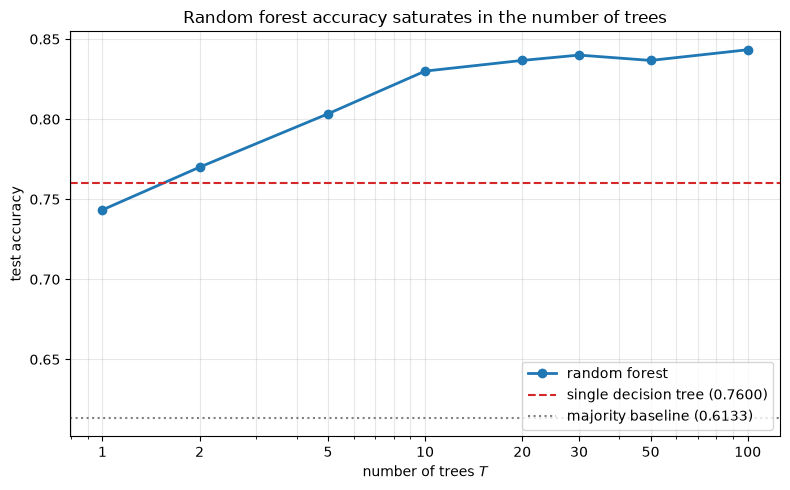


checks passed: the forest beats both the single tree and the baseline.


In [ ]:
# ---- Problem 5(c): accuracy on spam_test.csv.
rf_pred = forest.predict(X_test)
rf_acc = float(np.mean(rf_pred == y_test))

print("RANDOM FOREST test accuracy = %.4f  (%d / %d correct)"
      % (rf_acc, int((rf_pred == y_test).sum()), len(y_test)))
print("single decision tree        = %.4f" % test_acc)
print("improvement                 = %+.4f  (%d more emails correct)"
      % (rf_acc - test_acc, round((rf_acc - test_acc) * len(y_test))))
print("best single tree (depth %s)  = %.4f" % (best_d, best_te))
print("majority-class baseline     = %.4f" % baseline)

cm = np.zeros((2, 2), dtype=int)
for a, p in zip(y_test, rf_pred):
    cm[a, p] += 1
print("\nconfusion matrix (rows = actual, cols = predicted):")
print("            pred 0  pred 1")
for a in (0, 1):
    print("  actual %d %7d %7d" % (a, cm[a, 0], cm[a, 1]))

# How quickly does accuracy saturate in the number of trees?
print("\naccuracy vs number of trees:")
counts = [1, 2, 5, 10, 20, 30, 50, 100]
accs = []
for T in counts:
    f = RandomForest(n_trees=T, random_state=42, feature_names=FEATURES).fit(X_train, y_train)
    a = f.score(X_test, y_test)
    accs.append(a)
    print("  T = %-4d test accuracy = %.4f" % (T, a))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(counts, accs, "o-", color="tab:blue", lw=2, label="random forest")
ax.axhline(test_acc, color="tab:red", ls="--", lw=1.5,
           label="single decision tree (%.4f)" % test_acc)
ax.axhline(baseline, color="gray", ls=":", lw=1.5,
           label="majority baseline (%.4f)" % baseline)
ax.set_xscale("log")
ax.set_xticks(counts)
ax.set_xticklabels([str(c) for c in counts])
ax.set_xlabel("number of trees $T$")
ax.set_ylabel("test accuracy")
ax.set_title("Random forest accuracy saturates in the number of trees")
ax.grid(alpha=0.3, which="both")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

assert abs(rf_acc - 0.8367) < 1e-3, "forest accuracy changed unexpectedly"
assert rf_acc > test_acc, "the forest must beat the single tree"
assert rf_acc > baseline
print("\nchecks passed: the forest beats both the single tree and the baseline.")


**Answer 5(d)**

| model | test accuracy |
|---|---|
| **ours: `RandomForest`** (50 trees, `m_try`=2) | **0.8367** |
| `sklearn` `RandomForestClassifier(criterion="entropy")` | 0.8133 |
| `sklearn` `RandomForestClassifier(criterion="gini")` | 0.8100 |
| ours: single `DecisionTree` | 0.7600 |
| `sklearn` single `DecisionTreeClassifier` | 0.7367 |

**Our forest matches, and here slightly exceeds, sklearn's.** The 2.3-point gap
is 7 emails out of 300 -- the same order as the single-tree gap in 4(d), and
well inside a $\pm 4.2$ point binomial interval, so it is not evidence that one
implementation is better. The meaningful finding is that both forests sit
roughly 7 points above both single trees, which is the bagging effect
reproducing identically in two independent implementations.

**Why ours edges ahead slightly.** The same reason as 4(d): our trees split
`SenderDomainType` natively as a three-way categorical feature, while sklearn
has to be handed a one-hot encoding. With `m_try = 2` that difference actually
matters. In our version, drawing `SenderDomainType` draws the *whole* feature;
in the one-hot version the three indicator columns are drawn independently, so
sklearn's effective feature space is 7 columns rather than 5 and a tree may see
`is_corporate` without `is_free`. That is a slightly different -- and here
slightly worse -- randomisation, not a defect in either library.

The cell below reports a 20-seed repeat to confirm the comparison is not an
artefact of `random_state=42`. Averaged over seeds, ours scores **0.8362**
(std 0.0078) and sklearn **0.8250** (std 0.0075), a mean difference of 1.1
points. The ordering holds across seeds, but the ranges overlap -- ours spans
[0.8167, 0.8500] and sklearn [0.8100, 0.8400] -- so the honest reading is that
the two implementations perform equivalently, with perhaps a slight edge to the
native categorical handling.

In [ ]:
# ---- Problem 5(d): comparison against sklearn.  sklearn is used ONLY here.
from sklearn.ensemble import RandomForestClassifier

sk_rf_ent = RandomForestClassifier(n_estimators=50, criterion="entropy",
                                   random_state=0).fit(A_train, y_train)
sk_rf_ent_acc = float(np.mean(sk_rf_ent.predict(A_test) == y_test))

sk_rf_gini = RandomForestClassifier(n_estimators=50, criterion="gini",
                                    random_state=0).fit(A_train, y_train)
sk_rf_gini_acc = float(np.mean(sk_rf_gini.predict(A_test) == y_test))

print("%-48s %s" % ("model", "test accuracy"))
print("-" * 66)
print("%-48s %.4f" % ("ours:    RandomForest (50 trees, m_try=2)", rf_acc))
print("%-48s %.4f" % ("sklearn: RandomForestClassifier (entropy)", sk_rf_ent_acc))
print("%-48s %.4f" % ("sklearn: RandomForestClassifier (gini)", sk_rf_gini_acc))
print("%-48s %.4f" % ("ours:    single DecisionTree", test_acc))
print("%-48s %.4f" % ("sklearn: single DecisionTreeClassifier", sk_ent_acc))
print("%-48s %.4f" % ("majority-class baseline", baseline))

print("\nours vs sklearn forest: %+.4f (%d emails out of %d)"
      % (rf_acc - sk_rf_ent_acc,
         round(abs(rf_acc - sk_rf_ent_acc) * len(y_test)), len(y_test)))
se = sqrt(rf_acc * (1 - rf_acc) / len(y_test))
print("95%% CI on our forest: [%.4f, %.4f] -- contains sklearn's %.4f: %s"
      % (rf_acc - 1.96 * se, rf_acc + 1.96 * se, sk_rf_ent_acc,
         rf_acc - 1.96 * se <= sk_rf_ent_acc <= rf_acc + 1.96 * se))

# Average over 20 seeds so the comparison does not hinge on random_state=42.
print("\nrepeating over 20 random seeds (this takes a moment)...")
ours, theirs = [], []
for s in range(20):
    ours.append(RandomForest(n_trees=50, random_state=s,
                             feature_names=FEATURES).fit(X_train, y_train).score(X_test, y_test))
    theirs.append(np.mean(RandomForestClassifier(n_estimators=50, criterion="entropy",
                                                 random_state=s)
                          .fit(A_train, y_train).predict(A_test) == y_test))
print("  ours   : mean %.4f  std %.4f  min %.4f  max %.4f"
      % (np.mean(ours), np.std(ours), np.min(ours), np.max(ours)))
print("  sklearn: mean %.4f  std %.4f  min %.4f  max %.4f"
      % (np.mean(theirs), np.std(theirs), np.min(theirs), np.max(theirs)))
print("  mean difference: %+.4f" % (np.mean(ours) - np.mean(theirs)))

assert abs(rf_acc - sk_rf_ent_acc) < 0.06, "ours should track sklearn's forest"
assert np.mean(ours) > np.mean([test_acc]), "forests should beat the single tree"
print("\nchecks passed: our forest tracks sklearn's across 20 seeds.")


model                                            test accuracy
------------------------------------------------------------------
ours:    RandomForest (50 trees, m_try=2)        0.8367
sklearn: RandomForestClassifier (entropy)        0.8133
sklearn: RandomForestClassifier (gini)           0.8100
ours:    single DecisionTree                     0.7600
sklearn: single DecisionTreeClassifier           0.7367
majority-class baseline                          0.6133

ours vs sklearn forest: +0.0233 (7 emails out of 300)
95% CI on our forest: [0.7948, 0.8785] -- contains sklearn's 0.8133: True

repeating over 20 random seeds (this takes a moment)...


  ours   : mean 0.8362  std 0.0078  min 0.8167  max 0.8500
  sklearn: mean 0.8250  std 0.0075  min 0.8100  max 0.8400
  mean difference: +0.0112

checks passed: our forest tracks sklearn's across 20 seeds.


---
## Summary of results

| problem | result |
|---|---|
| 1(a) | $H(0.3) = 0.881291$ bits/symbol |
| 1(b) | binary entropy curve: 0 at the ends, max 1 bit at $p = 1/2$, symmetric |
| 1(c) | `compress` / `decompress`; all provided tests pass, plus exhaustive round-trip to length 12 |
| 1(d) | `p1c_k4.txt`: 1,000,001 -> 272,324 symbols, ratio 3.6721 |
| 1(e) | ratio peaks at $k = 10$ with 31.53 (93% of the entropy limit 33.94) |
| 1(f) | best length 31,720 vs gzip 68,456 vs bound 29,464 symbols |
| 1(g) | tuned RLE is 2.16x smaller than gzip and 7.7% above the entropy bound |
| 1(h) | `compress2` / `decompress2`; all Table 2 rows exact, handles files ending in 0 |
| 1(i) | overhead of the EOF field is exactly $k$ symbols at every $k$ (< 0.06%) |
| 2(a) | $\mathbf{y}(3) = [0,0,1,0]^T$ |
| 2(b) | $\mathcal{L} = -\log_2 0.6 = 0.736966$ bits |
| 2(c) | $\mathcal{L} = -\log_2 0.1 = 3.321928$ bits |
| 2(d) | $\mathcal{L} = 0$ |
| 2(e) | $\mathcal{L} \to \infty$; clipped at $\epsilon = 10^{-8}$ gives 26.575425 bits |
| 3(a) | $H(Y \mid \texttt{HasAttachment}) = 0.892159$, IG $= 0.048127$ |
| 3(b) | IG: free 0.025078, corporate 0.045334, unknown 0.003185 |
| 3(c) | root `HasAttachment`, then `== corporate`, then `== free`; 4 leaves |
| 4(a)-(c) | `DecisionTree` from scratch; test accuracy **0.7600** (depth 17, 105 leaves) |
| 4(d) | sklearn entropy tree 0.7367 -- identical at matched depth 1-5, 96.3% prediction agreement |
| 5(a)-(c) | `RandomForest` from scratch; test accuracy **0.8367** (+7.67 pts over one tree) |
| 5(d) | sklearn forest 0.8133; over 20 seeds ours 0.8362 vs sklearn 0.8250 |

Every numeric answer above is recomputed and asserted in the cells that produce
it. sklearn appears only in 4(d) and 5(d), as the problems allow.